# Student Placement Clustering Analysis

A comparative study of unsupervised machine learning algorithms (K-Means, Agglomerative Hierarchical, DBSCAN, Gaussian Mixture Models) across multiple feature selection and dimensionality reduction strategies.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dynamically resolve project directory whether running from repo root or notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'Placement_Data_Original.csv'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'Placement_Data_Cleaned.csv'
FIGURES_DIR = PROJECT_ROOT / 'outputs' / 'figures'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load original untouched dataset
df = pd.read_csv(RAW_DATA_PATH)
print(f"Loaded raw dataset from: {RAW_DATA_PATH} (Shape: {df.shape})")
df.head()


Loaded raw dataset from: C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\data\raw\Placement_Data_Original.csv (Shape: (215, 15))


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


Phase 2: Dataset Study
Study
• Source https://www.kaggle.com/datasets/benroshan/factors-affecting-campus-placement?utm_source=chatgpt.com
• Number of records (Instances)
• Features
• Target (if available)
• Missing values
• Data types
Deliverable
Dataset Description Report

In [2]:
# Number of records and features
print("Shape (rows, columns):", df.shape)

# Feature names
print("\nColumns:", list(df.columns))

# Data types
print("\nData Types:\n", df.dtypes)

# Missing values
print("\nMissing Values:\n", df.isnull().sum())

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Target variable distribution
print("\nTarget (status) distribution:\n", df['status'].value_counts())

# Summary statistics
df.describe(include='all')

Shape (rows, columns): (215, 15)

Columns: ['sl_no', 'gender', 'ssc_p', 'ssc_b', 'hsc_p', 'hsc_b', 'hsc_s', 'degree_p', 'degree_t', 'workex', 'etest_p', 'specialisation', 'mba_p', 'status', 'salary']

Data Types:
 sl_no               int64
gender             object
ssc_p             float64
ssc_b              object
hsc_p             float64
hsc_b              object
hsc_s              object
degree_p          float64
degree_t           object
workex             object
etest_p           float64
specialisation     object
mba_p             float64
status             object
salary            float64
dtype: object

Missing Values:
 sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

Duplicate rows: 0

Target (status) 

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
count,215.000000,215,215.000000,215,215.000000,215,215,215.000000,215,215,215.000000,215,215.000000,215,148.000000
unique,NaN,2,NaN,2,NaN,2,3,NaN,3,2,NaN,2,NaN,2,NaN
top,NaN,M,NaN,Central,NaN,Others,Commerce,NaN,Comm&Mgmt,No,NaN,Mkt&Fin,NaN,Placed,NaN
freq,NaN,139,NaN,116,NaN,131,113,NaN,145,141,NaN,120,NaN,148,NaN
mean,108.000000,NaN,67.303395,NaN,66.333163,NaN,NaN,66.370186,NaN,NaN,72.100558,NaN,62.278186,NaN,288655.405405
std,62.209324,NaN,10.827205,NaN,10.897509,NaN,NaN,7.358743,NaN,NaN,13.275956,NaN,5.833385,NaN,93457.452420
min,1.000000,NaN,40.890000,NaN,37.000000,NaN,NaN,50.000000,NaN,NaN,50.000000,NaN,51.210000,NaN,200000.000000
25%,54.500000,NaN,60.600000,NaN,60.900000,NaN,NaN,61.000000,NaN,NaN,60.000000,NaN,57.945000,NaN,240000.000000
50%,108.000000,NaN,67.000000,NaN,65.000000,NaN,NaN,66.000000,NaN,NaN,71.000000,NaN,62.000000,NaN,265000.000000
75%,161.500000,NaN,75.700000,NaN,73.000000,NaN,NaN,72.000000,NaN,NaN,83.500000,NaN,66.255000,NaN,300000.000000


Phase 3: Data Preprocessing
Perform
• Missing value handling
• Duplicate removal
• Outlier detection
• Encoding
• Feature Scaling
• Data Visualization
Deliverable
Preprocessed Dataset


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(RAW_DATA_PATH)
df.head()


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [4]:
## 3.1 Missing Value Handling
print("Missing values before handling:\n", df.isnull().sum())

# 'salary' is missing only for students who were NOT placed — this is logical,
# not an error (no salary if not placed). We fill it with 0 to keep the
# column numeric and usable, since it will be excluded from clustering anyway.
df['salary'] = df['salary'].fillna(0)

print("\nMissing values after handling:\n", df.isnull().sum())

Missing values before handling:
 sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

Missing values after handling:
 sl_no             0
gender            0
ssc_p             0
ssc_b             0
hsc_p             0
hsc_b             0
hsc_s             0
degree_p          0
degree_t          0
workex            0
etest_p           0
specialisation    0
mba_p             0
status            0
salary            0
dtype: int64


In [5]:
## 3.2 Duplicate Removal
print("Duplicate rows before removal:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after removal:", df.duplicated().sum())
print("Shape after duplicate removal:", df.shape)

Duplicate rows before removal: 0
Duplicate rows after removal: 0
Shape after duplicate removal: (215, 15)


In [6]:
## 3.3 Outlier Detection (IQR Method)
numeric_cols = ['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'salary']

def detect_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data[col] < lower) | (data[col] > upper)]
    return outliers, lower, upper

for col in numeric_cols:
    outliers, lower, upper = detect_outliers_iqr(df, col)
    print(f"{col}: {len(outliers)} outliers | valid range = [{lower:.2f}, {upper:.2f}]")

ssc_p: 0 outliers | valid range = [37.95, 98.35]
hsc_p: 8 outliers | valid range = [42.75, 91.15]
degree_p: 1 outliers | valid range = [44.50, 88.50]
etest_p: 0 outliers | valid range = [24.75, 118.75]
mba_p: 0 outliers | valid range = [45.48, 78.72]
salary: 1 outliers | valid range = [-423750.00, 706250.00]


Boxplots to visualize outliers

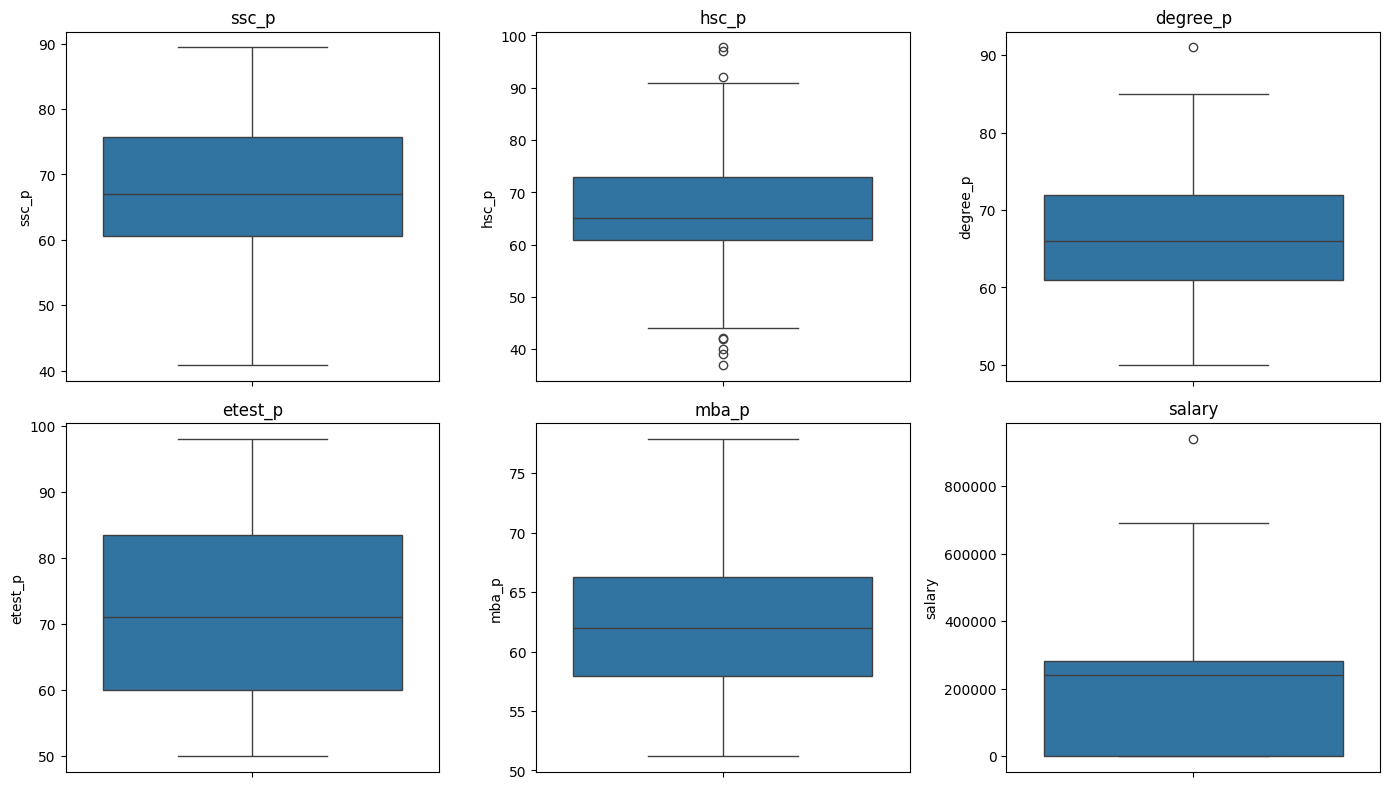

In [7]:
plt.figure(figsize=(14, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_outlier_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
## 3.4 Encoding Categorical Variables
# Binary categorical columns -> Label Encoding (0/1)
binary_cols = ['gender', 'ssc_b', 'hsc_b', 'workex', 'specialisation', 'status']

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

df_encoded = df.copy()
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])

# Multi-category columns -> One-Hot Encoding
multi_cols = ['hsc_s', 'degree_t']
df_encoded = pd.get_dummies(df_encoded, columns=multi_cols, drop_first=True)

print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Shape after encoding: (215, 17)


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status,salary,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech
0,1,1,67.00,1,91.00,1,58.00,0,55.0,1,58.80,1,270000.0,True,False,False,True
1,2,1,79.33,0,78.33,1,77.48,1,86.5,0,66.28,1,200000.0,False,True,False,True
2,3,1,65.00,0,68.00,0,64.00,0,75.0,0,57.80,1,250000.0,False,False,False,False
3,4,1,56.00,0,52.00,0,52.00,0,66.0,1,59.43,0,0.0,False,True,False,True
4,5,1,85.80,0,73.60,0,73.30,0,96.8,0,55.50,1,425000.0,True,False,False,False


In [9]:
## 3.5 Feature Scaling
from sklearn.preprocessing import StandardScaler

# Features used for clustering (exclude identifier, target, and salary —
# salary/status will only be used later for post-clustering placement analysis)
cluster_features = [c for c in df_encoded.columns if c not in ['sl_no', 'status', 'salary']]

scaler = StandardScaler()
df_scaled = df_encoded.copy()
df_scaled[cluster_features] = scaler.fit_transform(df_encoded[cluster_features])

df_scaled.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status,salary,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech
0,1,0.739434,-0.028087,1.082459,2.268812,0.800763,-1.140102,-0.724446,-1.291091,1.123903,-0.597647,1,270000.0,0.950082,-0.856663,-0.23221,1.626059
1,2,0.739434,1.113369,-0.923823,1.103448,0.800763,1.513267,1.380364,1.087157,-0.889757,0.687620,1,200000.0,-1.052541,1.167321,-0.23221,1.626059
2,3,0.739434,-0.213238,-0.923823,0.153313,-1.248809,-0.322843,-0.724446,0.218908,-0.889757,-0.769474,1,250000.0,-1.052541,-0.856663,-0.23221,-0.614984
3,4,0.739434,-1.046417,-0.923823,-1.318339,-1.248809,-1.957362,-0.724446,-0.460592,1.123903,-0.489396,0,0.0,-1.052541,1.167321,-0.23221,1.626059
4,5,0.739434,1.712332,-0.923823,0.668391,-1.248809,0.943909,-0.724446,1.864806,-0.889757,-1.164676,1,425000.0,0.950082,-0.856663,-0.23221,-0.614984


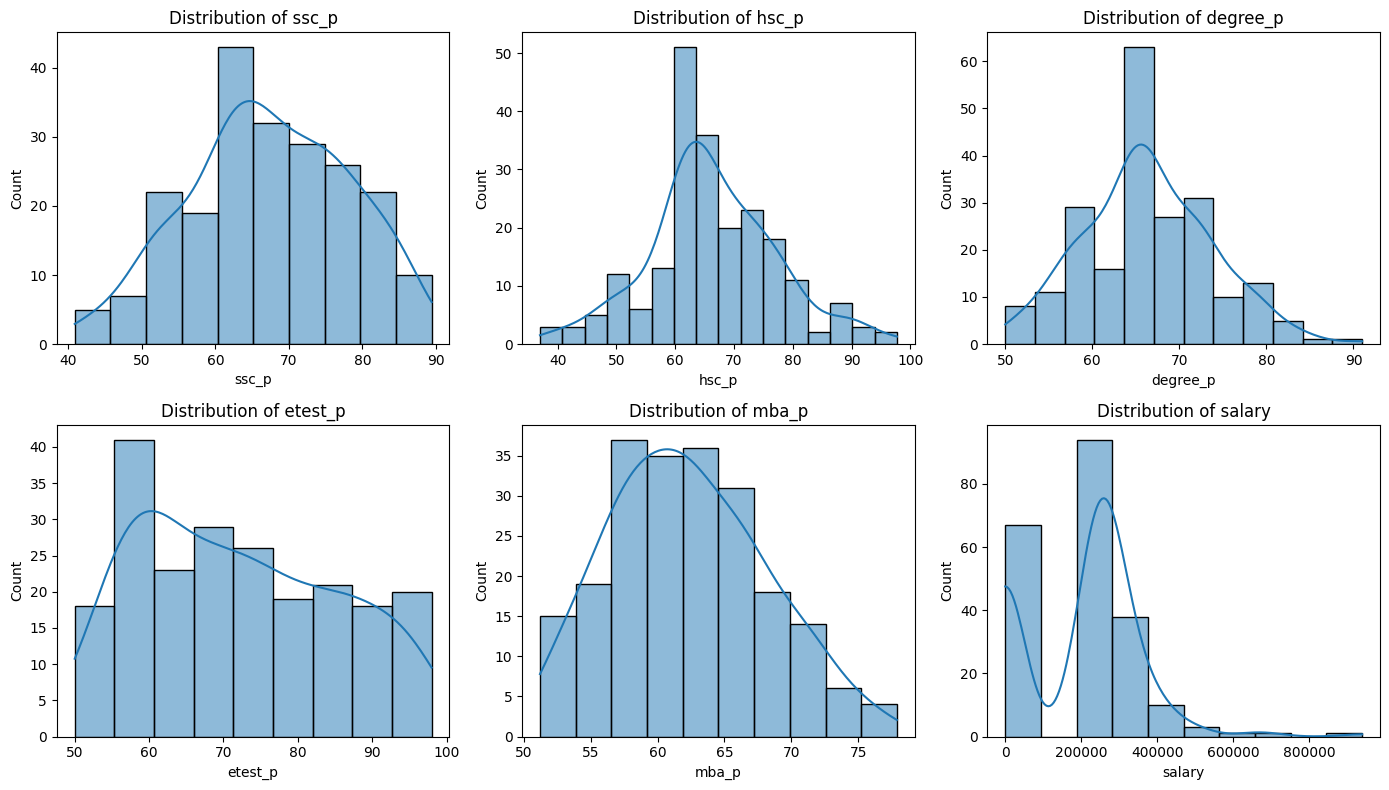

In [10]:
## 3.6 data Visualization

plt.figure(figsize=(14,8))
for i , col in enumerate(numeric_cols,1):
    plt.subplot(2,3,i)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_numeric_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


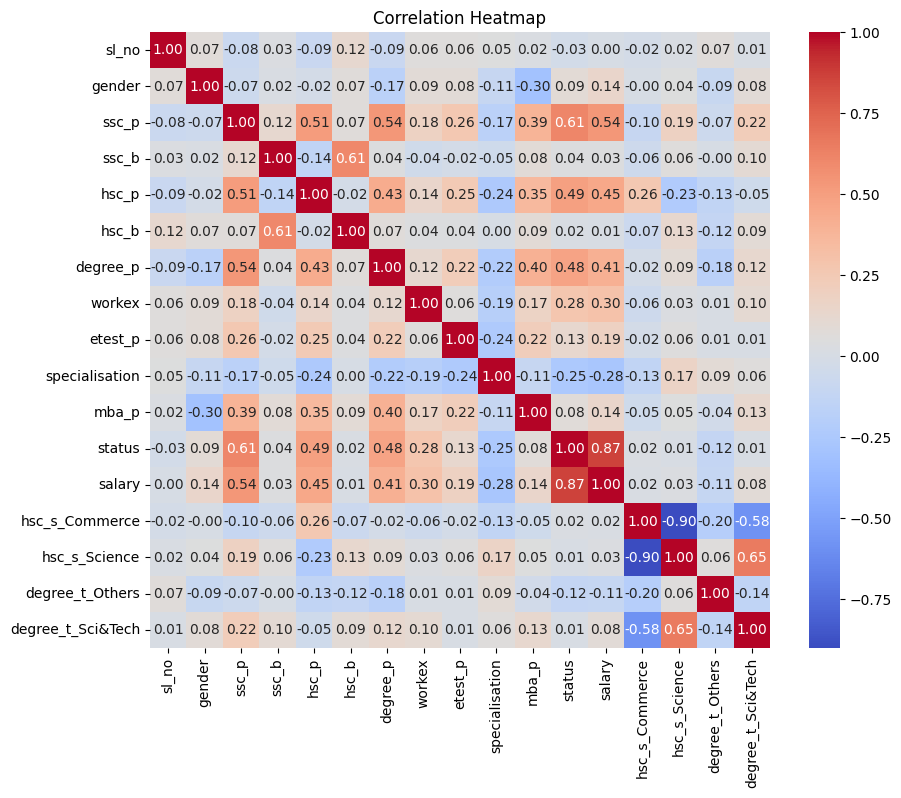

In [11]:
##Correlation heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(
    df_encoded.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.savefig(FIGURES_DIR / "03_correlation_heatmap_encoded.png", dpi=300, bbox_inches="tight")
plt.show()

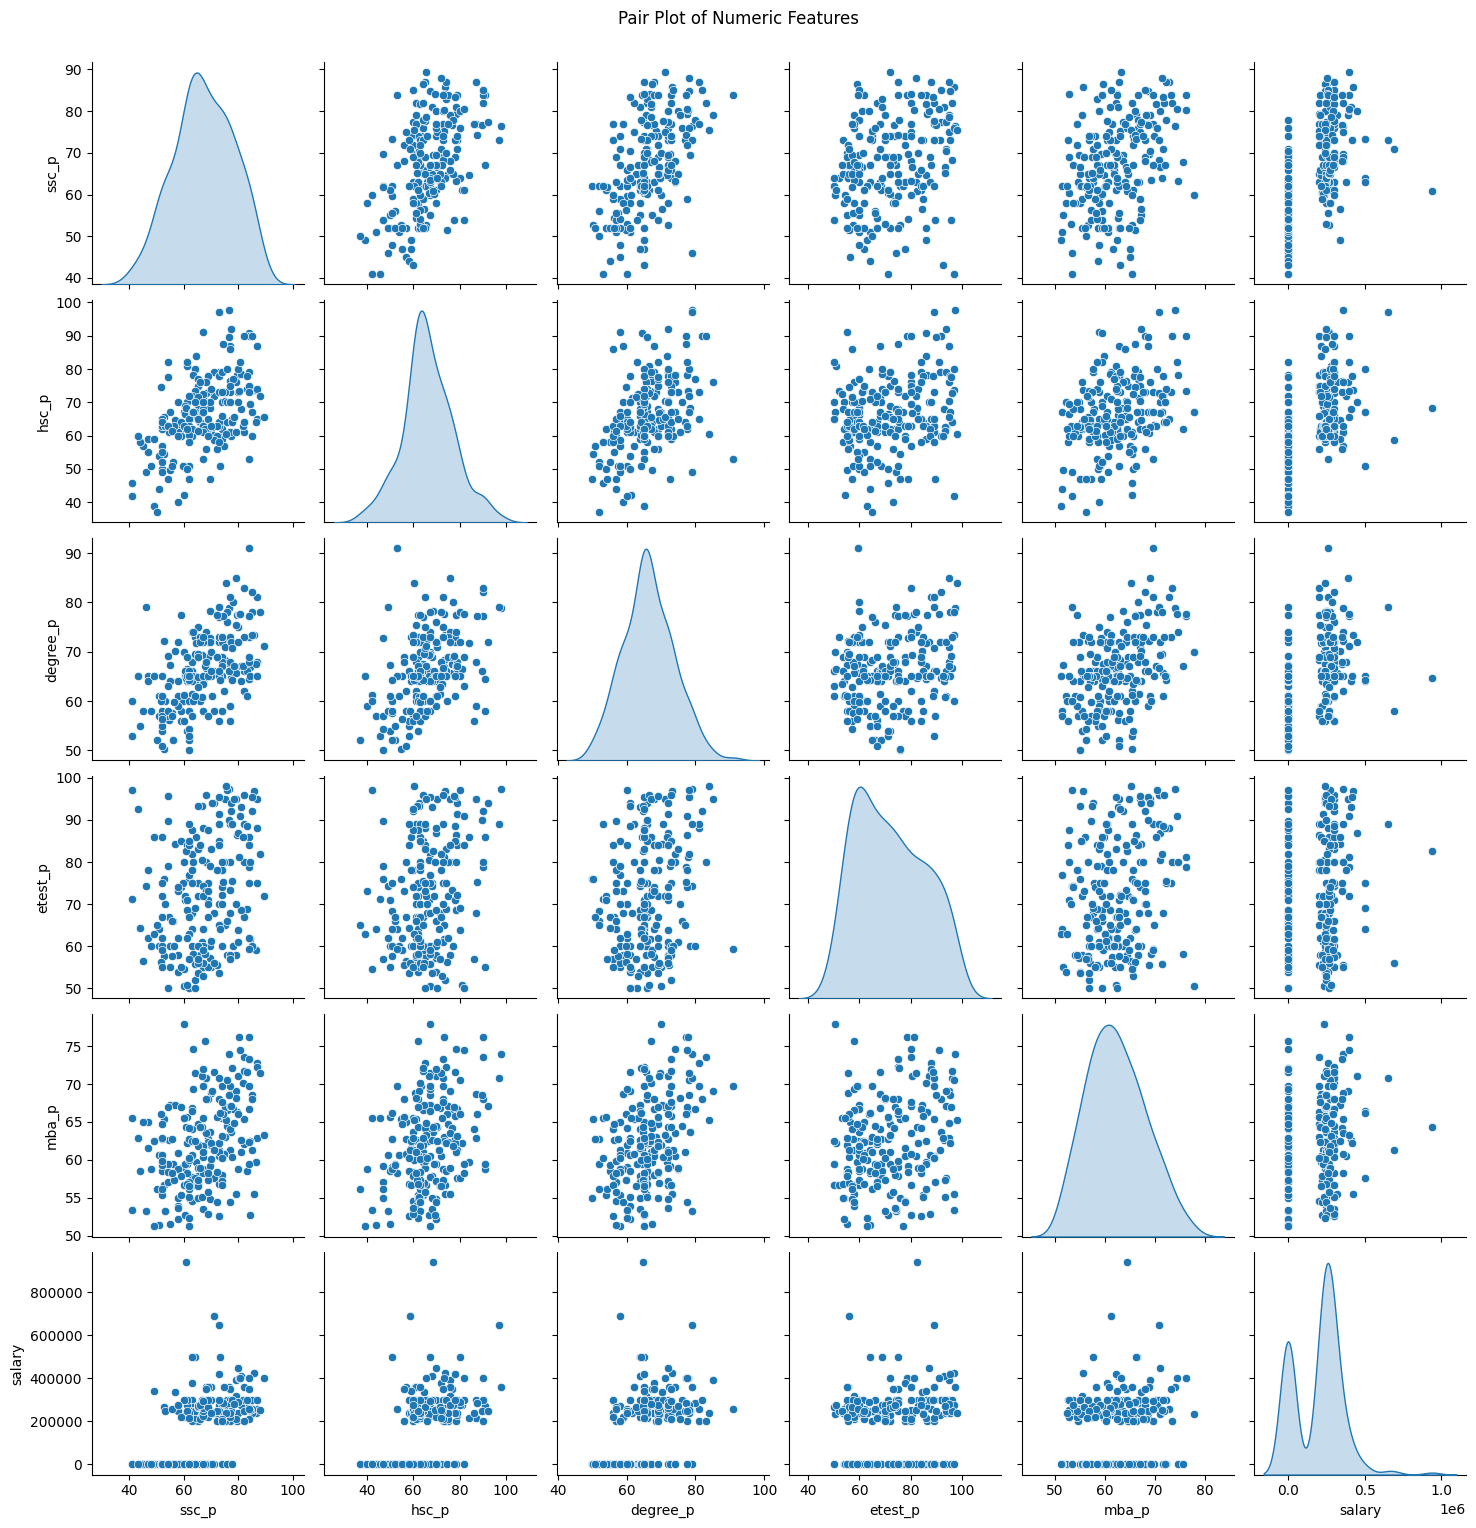

In [12]:
sns.pairplot(df[numeric_cols[:-1] + ['status'] if False else numeric_cols], diag_kind='kde')
plt.suptitle("Pair Plot of Numeric Features", y=1.02)
plt.savefig(FIGURES_DIR / "04_numeric_pairplot.png", dpi=300, bbox_inches="tight")
plt.show()

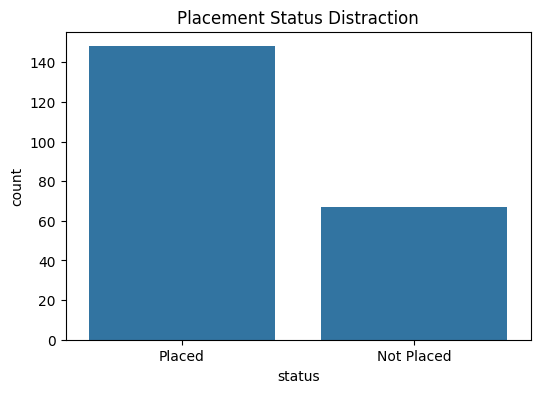

In [13]:
plt.figure(figsize=(6,4))
sns.countplot(x='status' , data=df)
plt.title("Placement Status Distraction")
plt.savefig(FIGURES_DIR / "05_placement_status_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
## 3.7 Save Preprocessed Dataset
df_scaled.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Preprocessed dataset saved as '{PROCESSED_DATA_PATH}'")
print("Final shape:", df_scaled.shape)


Preprocessed dataset saved as 'C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\data\processed\Placement_Data_Cleaned.csv'
Final shape: (215, 17)


In [15]:
# Phase 4: Feature Selection / Dimensionality Reduction
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA

# Load the preprocessed dataset (output of Phase 3)
df_scaled = pd.read_csv(PROCESSED_DATA_PATH)
print("Preprocessed dataset shape:", df_scaled.shape)

# Define feature set used for clustering
# (exclude identifier, target, and salary - not used as clustering inputs)
cluster_features = [c for c in df_scaled.columns if c not in ['sl_no', 'status', 'salary']]

X = df_scaled[cluster_features]
y = df_scaled['status']   # only used to guide Mutual Information, not used in clustering

print("Number of original features:", X.shape[1])
X.head()


Preprocessed dataset shape: (215, 17)
Number of original features: 14


,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech
0,0.739434,-0.028087,1.082459,2.268812,0.800763,-1.140102,-0.724446,-1.291091,1.123903,-0.597647,0.950082,-0.856663,-0.23221,1.626059
1,0.739434,1.113369,-0.923823,1.103448,0.800763,1.513267,1.380364,1.087157,-0.889757,0.687620,-1.052541,1.167321,-0.23221,1.626059
2,0.739434,-0.213238,-0.923823,0.153313,-1.248809,-0.322843,-0.724446,0.218908,-0.889757,-0.769474,-1.052541,-0.856663,-0.23221,-0.614984
3,0.739434,-1.046417,-0.923823,-1.318339,-1.248809,-1.957362,-0.724446,-0.460592,1.123903,-0.489396,-1.052541,1.167321,-0.23221,1.626059
4,0.739434,1.712332,-0.923823,0.668391,-1.248809,0.943909,-0.724446,1.864806,-0.889757,-1.164676,0.950082,-0.856663,-0.23221,-0.614984


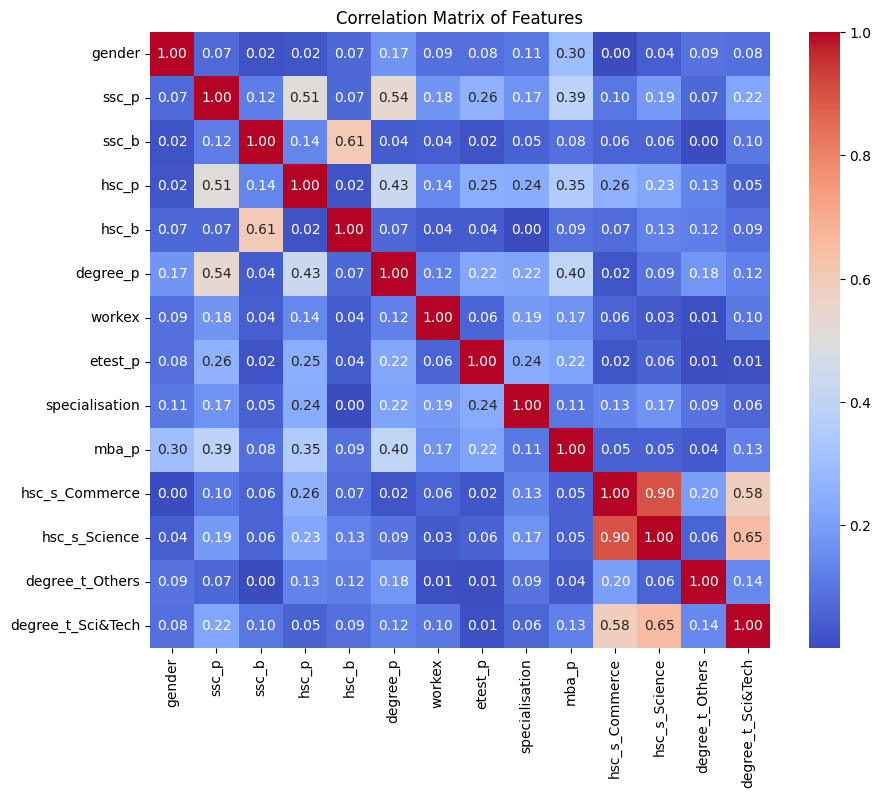


[Method 1] Highly correlated features to drop (threshold=0.85): ['hsc_s_Science']
[Method 1] Shape after Correlation-Based Selection: (215, 13)


In [16]:
# ============================================================
# Method 1: Correlation-Based Feature Selection
# ============================================================
corr_matrix = X.corr().abs()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Features")
plt.savefig(FIGURES_DIR / "06_feature_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

threshold = 0.85
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_triangle.columns if any(upper_triangle[col] > threshold)]

print(f"\n[Method 1] Highly correlated features to drop (threshold={threshold}):", to_drop)

X_corr_selected = X.drop(columns=to_drop)
print("[Method 1] Shape after Correlation-Based Selection:", X_corr_selected.shape)

dataset_v2 = X_corr_selected.copy()
# dataset_v2 kept in-memory for clustering experiments



[Method 2] Mutual Information Scores:
ssc_p                0.251744
hsc_p                0.170219
degree_p             0.165606
workex               0.058187
degree_t_Sci&Tech    0.055060
mba_p                0.031436
ssc_b                0.013639
gender               0.000000
hsc_b                0.000000
etest_p              0.000000
specialisation       0.000000
hsc_s_Commerce       0.000000
hsc_s_Science        0.000000
degree_t_Others      0.000000
dtype: float64


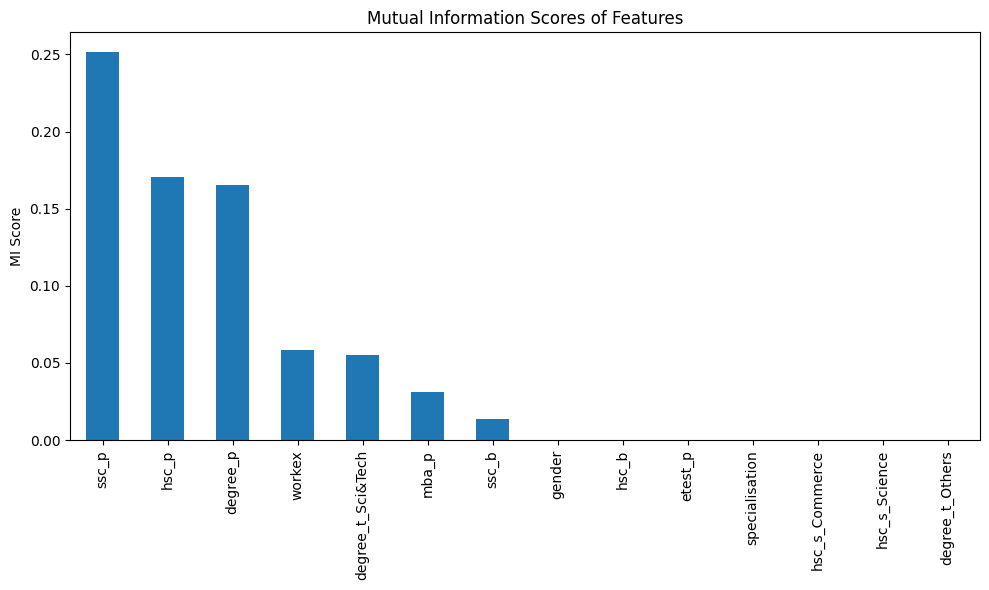


[Method 2] Top 8 features selected: ['ssc_p', 'hsc_p', 'degree_p', 'workex', 'degree_t_Sci&Tech', 'mba_p', 'ssc_b', 'gender']
[Method 2] Shape after Mutual Information Selection: (215, 8)


In [17]:
# ============================================================
# Method 2: Mutual Information
# ============================================================
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

print("\n[Method 2] Mutual Information Scores:")
print(mi_series)

plt.figure(figsize=(10, 6))
mi_series.plot(kind='bar')
plt.title("Mutual Information Scores of Features")
plt.ylabel("MI Score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_mutual_information_scores.png", dpi=300, bbox_inches="tight")
plt.show()

top_k = 8
selected_mi_features = mi_series.head(top_k).index.tolist()
print(f"\n[Method 2] Top {top_k} features selected:", selected_mi_features)

X_mi_selected = X[selected_mi_features]
print("[Method 2] Shape after Mutual Information Selection:", X_mi_selected.shape)

dataset_v3 = X_mi_selected.copy()
# dataset_v3 kept in-memory for clustering experiments


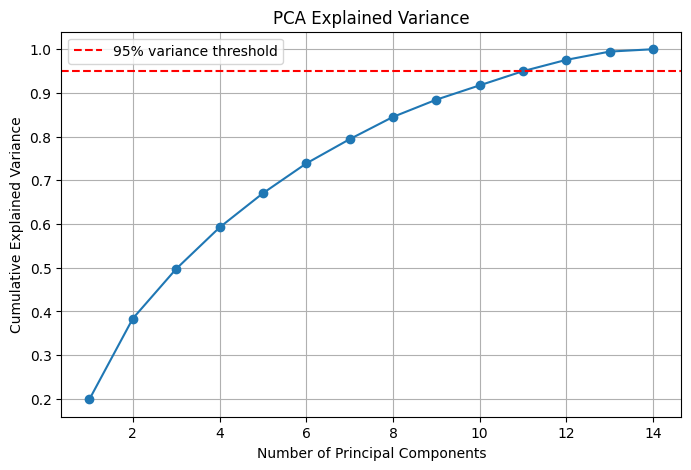


[Method 3] Original number of features: 14
[Method 3] Components needed for 95% variance: 12
[Method 3] Cumulative explained variance: 0.9757
[Method 3] Shape after PCA: (215, 12)


In [18]:
# ============================================================
# Method 3: Principal Component Analysis (PCA) — 95% Variance
# ============================================================
pca_full = PCA()
pca_full.fit(X)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% variance threshold')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(True)
plt.savefig(FIGURES_DIR / "08_pca_explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"\n[Method 3] Original number of features: {X.shape[1]}")
print(f"[Method 3] Components needed for 95% variance: {n_components_95}")
print(f"[Method 3] Cumulative explained variance: {cumulative_variance[n_components_95 - 1]:.4f}")

pca = PCA(n_components=n_components_95)
X_pca = pca.fit_transform(X)

pca_columns = [f"PC{i+1}" for i in range(n_components_95)]
X_pca_df = pd.DataFrame(X_pca, columns=pca_columns)
print("[Method 3] Shape after PCA:", X_pca_df.shape)

dataset_v4 = X_pca_df.copy()
# dataset_v4 kept in-memory for clustering experiments


In [19]:
# ============================================================
# Summary of Feature Selection & Dimensionality Reduction Versions
# ============================================================
dataset_v1 = X.copy()  # Version 1: Original scaled features

print("\n================ FEATURE SELECTION SUMMARY ================")
print(f"Dataset Version 1 (Original):             {dataset_v1.shape}")
print(f"Dataset Version 2 (Correlation Selection): {dataset_v2.shape}")
print(f"Dataset Version 3 (Mutual Information):    {dataset_v3.shape}")
print(f"Dataset Version 4 (PCA 95% variance):      {dataset_v4.shape}")
print("=============================================================")



================ FEATURE SELECTION SUMMARY ================
Dataset Version 1 (Original):             (215, 14)
Dataset Version 2 (Correlation Selection): (215, 13)
Dataset Version 3 (Mutual Information):    (215, 8)
Dataset Version 4 (PCA 95% variance):      (215, 12)


In [20]:
# Phase 5: Clustering
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
import time

# Dictionary containing all four dataset versions produced in Phase 4
datasets = {
    "Original": dataset_v1,
    "CorrelationSelection": dataset_v2,
    "MutualInformation": dataset_v3,
    "PCA95": dataset_v4
}

for name, d in datasets.items():
    print(f"{name}: shape = {d.shape}")


Original: shape = (215, 14)
CorrelationSelection: shape = (215, 13)
MutualInformation: shape = (215, 8)
PCA95: shape = (215, 12)


C:\Users\Nandini\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Nandini\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_

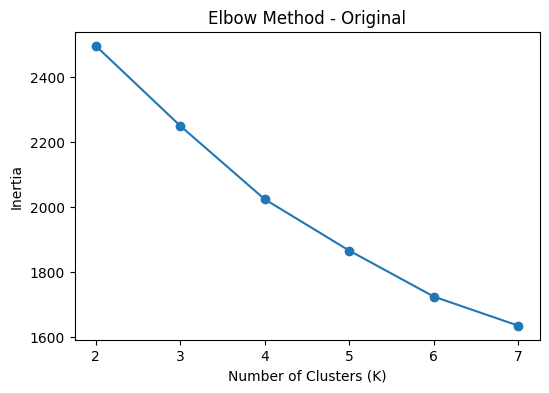

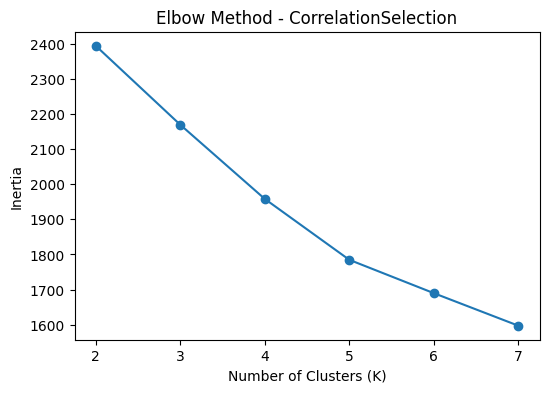

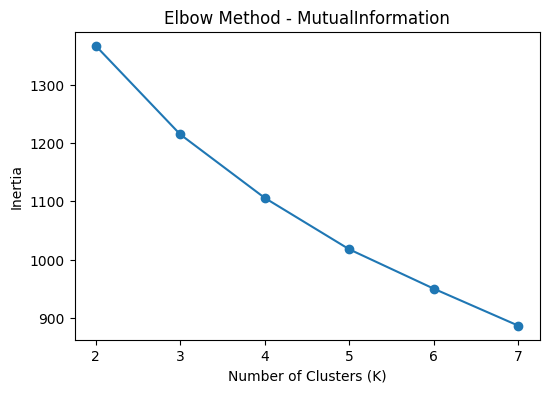

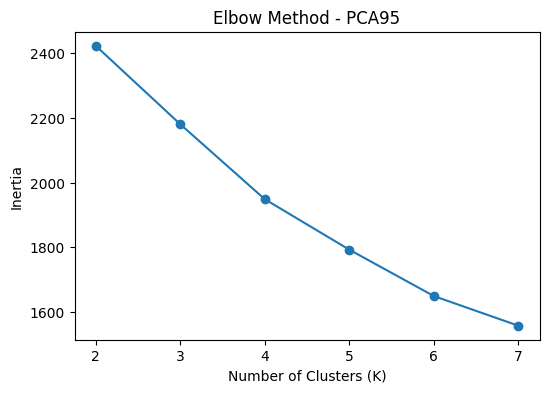

In [21]:
# ------------------------------------------------------------
# Helper: Elbow Method for K-Means (choose K)
# ------------------------------------------------------------
def plot_elbow(data, title):
    inertias = []
    K_range = range(2, 8)
    for k in K_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(data)
        inertias.append(km.inertia_)
    plt.figure(figsize=(6, 4))
    plt.plot(K_range, inertias, marker='o')
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Inertia")
    plt.title(f"Elbow Method - {title}")
    plt.savefig(FIGURES_DIR / f"09_elbow_method_{title}.png", dpi=300, bbox_inches="tight")
    plt.show()

for name, d in datasets.items():
    plot_elbow(d.values, name)



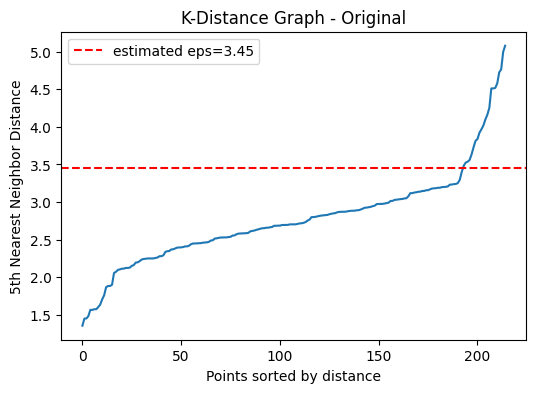

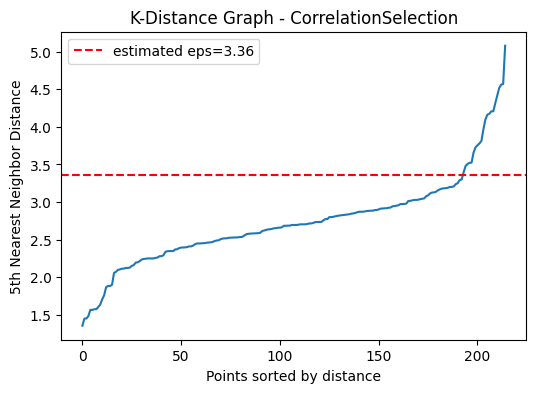

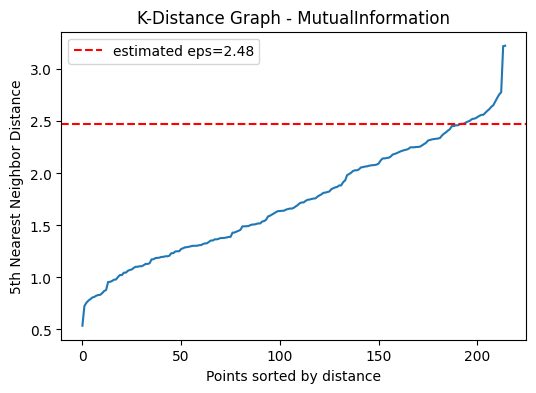

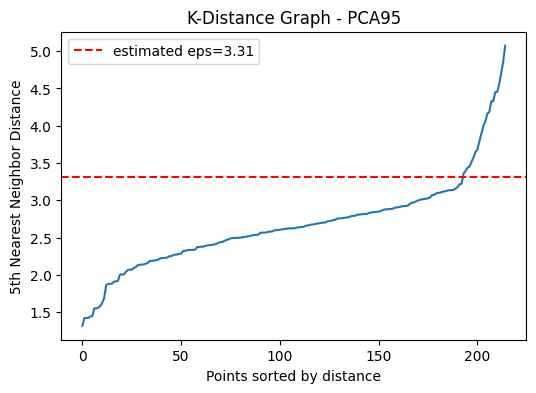

In [22]:
# ------------------------------------------------------------
# Helper: Estimate a good DBSCAN eps using k-distance graph
# ------------------------------------------------------------
def estimate_eps(data, k=5):
    nn = NearestNeighbors(n_neighbors=k).fit(data)
    distances, _ = nn.kneighbors(data)
    distances = np.sort(distances[:, k - 1])
    # use the 90th percentile distance as a practical eps estimate
    eps = np.percentile(distances, 90)
    return eps, distances

for name, d in datasets.items():
    eps, distances = estimate_eps(d.values)
    plt.figure(figsize=(6, 4))
    plt.plot(distances)
    plt.axhline(y=eps, color='r', linestyle='--', label=f'estimated eps={eps:.2f}')
    plt.title(f"K-Distance Graph - {name}")
    plt.xlabel("Points sorted by distance")
    plt.ylabel("5th Nearest Neighbor Distance")
    plt.legend()
    plt.show()

In [23]:
# ------------------------------------------------------------
# Run all 4 clustering algorithms on all 4 dataset versions
# ------------------------------------------------------------

K_FIXED = 3          # number of clusters for K-Means, Hierarchical, GMM
                     # (adjust based on elbow plots / domain knowledge)
MIN_SAMPLES = 5      # DBSCAN min_samples

cluster_results = {}  # stores cluster labels for later evaluation/visualization

for name, d in datasets.items():
    X = d.values
    eps, _ = estimate_eps(X, k=5)

    print(f"\n===== Dataset: {name} | shape={X.shape} | DBSCAN eps={eps:.2f} =====")

    # Algorithm 1: K-Means
    start = time.time()
    kmeans = KMeans(n_clusters=K_FIXED, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(X)
    kmeans_time = time.time() - start

    # Algorithm 2: Agglomerative Hierarchical Clustering
    start = time.time()
    hierarchical = AgglomerativeClustering(n_clusters=K_FIXED)
    hierarchical_labels = hierarchical.fit_predict(X)
    hierarchical_time = time.time() - start

    # Algorithm 3: DBSCAN
    start = time.time()
    dbscan = DBSCAN(eps=eps, min_samples=MIN_SAMPLES)
    dbscan_labels = dbscan.fit_predict(X)
    dbscan_time = time.time() - start

    n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    n_noise = list(dbscan_labels).count(-1)

    # Algorithm 4: Gaussian Mixture Model (GMM)
    start = time.time()
    gmm = GaussianMixture(n_components=K_FIXED, random_state=42)
    gmm_labels = gmm.fit_predict(X)
    gmm_time = time.time() - start

    # Print results
    print(f"K-Means:      clusters={len(set(kmeans_labels))}, time={kmeans_time:.4f}s")
    print(f"Hierarchical: clusters={len(set(hierarchical_labels))}, time={hierarchical_time:.4f}s")
    print(f"DBSCAN:       clusters={n_clusters_dbscan}, noise points={n_noise}, time={dbscan_time:.4f}s")
    print(f"GMM:          clusters={len(set(gmm_labels))}, time={gmm_time:.4f}s")

    # Store results
    cluster_results[name] = {
        "KMeans": {
            "labels": kmeans_labels,
            "time": kmeans_time
        },

        "Hierarchical": {
            "labels": hierarchical_labels,
            "time": hierarchical_time
        },

        "DBSCAN": {
            "labels": dbscan_labels,
            "time": dbscan_time,
            "n_clusters": n_clusters_dbscan,
            "n_noise": n_noise
        },

        "GMM": {
            "labels": gmm_labels,
            "time": gmm_time
        }
    }


===== Dataset: Original | shape=(215, 14) | DBSCAN eps=3.45 =====
K-Means:      clusters=3, time=0.0313s
Hierarchical: clusters=3, time=0.0134s
DBSCAN:       clusters=1, noise points=16, time=0.0041s
GMM:          clusters=3, time=0.0160s

===== Dataset: CorrelationSelection | shape=(215, 13) | DBSCAN eps=3.36 =====
K-Means:      clusters=3, time=0.0365s
Hierarchical: clusters=3, time=0.0019s
DBSCAN:       clusters=1, noise points=15, time=0.0041s
GMM:          clusters=3, time=0.0184s

===== Dataset: MutualInformation | shape=(215, 8) | DBSCAN eps=2.48 =====
K-Means:      clusters=3, time=0.0345s
Hierarchical: clusters=3, time=0.0019s
DBSCAN:       clusters=1, noise points=4, time=0.0029s
GMM:          clusters=3, time=0.0125s

===== Dataset: PCA95 | shape=(215, 12) | DBSCAN eps=3.31 =====


K-Means:      clusters=3, time=0.0360s
Hierarchical: clusters=3, time=0.0020s
DBSCAN:       clusters=1, noise points=16, time=0.0037s
GMM:          clusters=3, time=0.0142s


In [24]:
# ------------------------------------------------------------
# Save cluster labels for each of the 16 experiments
# ------------------------------------------------------------
for name, d in datasets.items():
    out = d.copy()
    out["KMeans_Cluster"] = cluster_results[name]["KMeans"]["labels"]
    out["Hierarchical_Cluster"] = cluster_results[name]["Hierarchical"]["labels"]
    out["DBSCAN_Cluster"] = cluster_results[name]["DBSCAN"]["labels"]
    out["GMM_Cluster"] = cluster_results[name]["GMM"]["labels"]
    out_path = RESULTS_DIR / f"Clustered_{name}.csv"
    out.to_csv(out_path, index=False)
    print(f"Saved: {out_path}")


Saved: C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\outputs\results\Clustered_Original.csv
Saved: C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\outputs\results\Clustered_CorrelationSelection.csv
Saved: C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\outputs\results\Clustered_MutualInformation.csv
Saved: C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\outputs\results\Clustered_PCA95.csv


In [25]:
# ------------------------------------------------------------
# Phase 6: Performance Evaluation
# ------------------------------------------------------------

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import pandas as pd
import numpy as np

evaluation_results = []

for dataset_name, d in datasets.items():

    X = d.values

    for algorithm in ["KMeans", "Hierarchical", "DBSCAN", "GMM"]:

        labels = cluster_results[dataset_name][algorithm]["labels"]
        execution_time = cluster_results[dataset_name][algorithm]["time"]

        # ----------------------------------------------------
        # Handle DBSCAN noise points
        # ----------------------------------------------------
        if algorithm == "DBSCAN":

            mask = labels != -1

            X_eval = X[mask]
            labels_eval = labels[mask]

            n_clusters = len(set(labels_eval))

        else:

            X_eval = X
            labels_eval = labels

            n_clusters = len(set(labels_eval))

        # ----------------------------------------------------
        # Calculate evaluation metrics
        # ----------------------------------------------------

        if n_clusters >= 2 and n_clusters < len(labels_eval):

            silhouette = silhouette_score(
                X_eval,
                labels_eval
            )

            davies_bouldin = davies_bouldin_score(
                X_eval,
                labels_eval
            )

            calinski_harabasz = calinski_harabasz_score(
                X_eval,
                labels_eval
            )

        else:

            silhouette = np.nan
            davies_bouldin = np.nan
            calinski_harabasz = np.nan

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        evaluation_results.append({
            "Dataset Version": dataset_name,
            "Algorithm": algorithm,
            "Silhouette Score": silhouette,
            "Davies-Bouldin Index": davies_bouldin,
            "Calinski-Harabasz Score": calinski_harabasz,
            "Execution Time (s)": execution_time,
            "Number of Clusters": n_clusters
        })


# ------------------------------------------------------------
# Create final evaluation table
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

print("\n================ PERFORMANCE EVALUATION ================\n")

display(evaluation_df)
evaluation_df.to_csv(RESULTS_DIR / 'Clustering_Evaluation_All_16_Experiments.csv', index=False)
print(f"Saved full 16-experiment evaluation to: {RESULTS_DIR / 'Clustering_Evaluation_All_16_Experiments.csv'}")



================ PERFORMANCE EVALUATION ================



,Dataset Version,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Execution Time (s),Number of Clusters
0,Original,KMeans,0.142606,2.034801,35.886800,0.031256,3
1,Original,Hierarchical,0.192364,1.772520,35.300068,0.013368,3
2,Original,DBSCAN,NaN,NaN,NaN,0.004073,1
3,Original,GMM,0.096124,2.736442,8.081671,0.016042,3
4,CorrelationSelection,KMeans,0.127657,2.144770,30.564656,0.036519,3
5,CorrelationSelection,Hierarchical,0.129569,2.193045,25.419923,0.001897,3
6,CorrelationSelection,DBSCAN,NaN,NaN,NaN,0.004147,1
7,CorrelationSelection,GMM,0.038299,3.304853,13.663014,0.018383,3
8,MutualInformation,KMeans,0.165395,2.004239,44.095371,0.034478,3
9,MutualInformation,Hierarchical,0.133673,2.153264,31.078996,0.001938,3


Saved full 16-experiment evaluation to: C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\outputs\results\Clustering_Evaluation_All_16_Experiments.csv


In [26]:
# ------------------------------------------------------------
# Verify total number of experiments
# ------------------------------------------------------------

print("\nTotal Experiments:", len(evaluation_df))

print("\nExperiments per Dataset:")
print(evaluation_df["Dataset Version"].value_counts())

print("\nExperiments per Algorithm:")
print(evaluation_df["Algorithm"].value_counts())


Total Experiments: 16

Experiments per Dataset:
Dataset Version
Original                4
CorrelationSelection    4
MutualInformation       4
PCA95                   4
Name: count, dtype: int64

Experiments per Algorithm:
Algorithm
KMeans          4
Hierarchical    4
DBSCAN          4
GMM             4
Name: count, dtype: int64


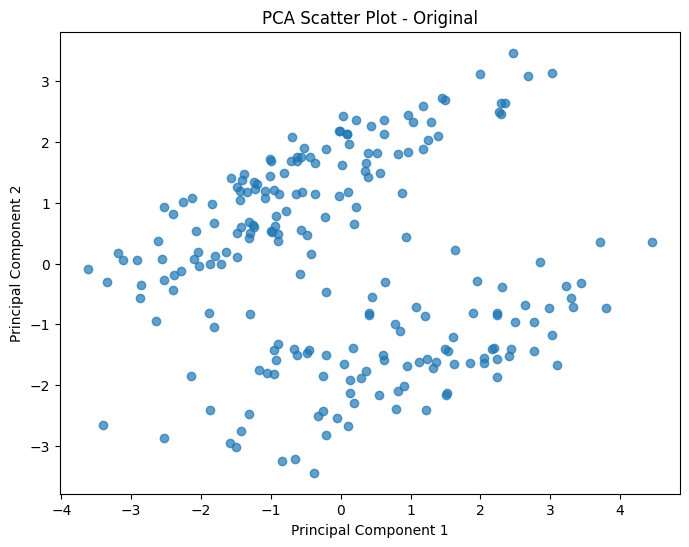

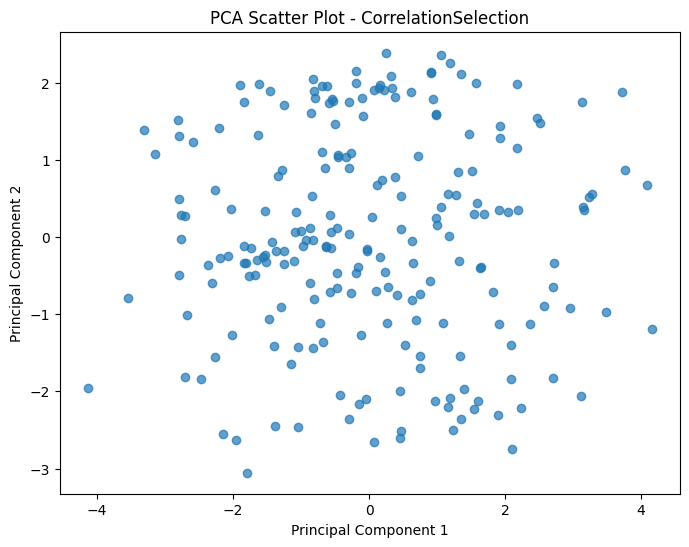

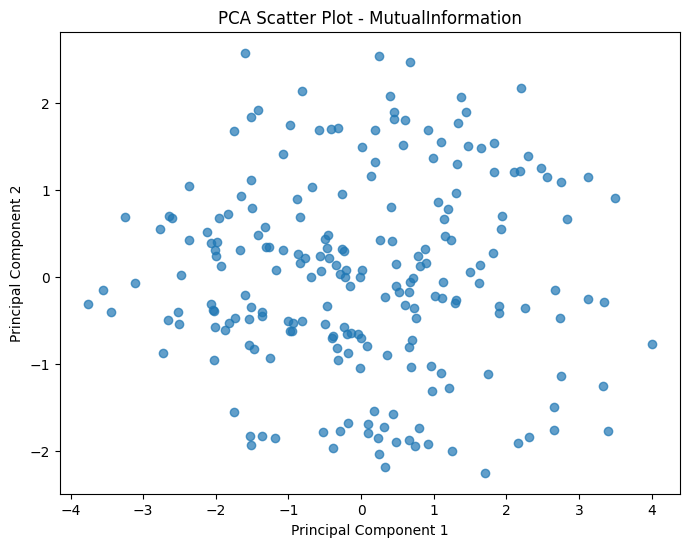

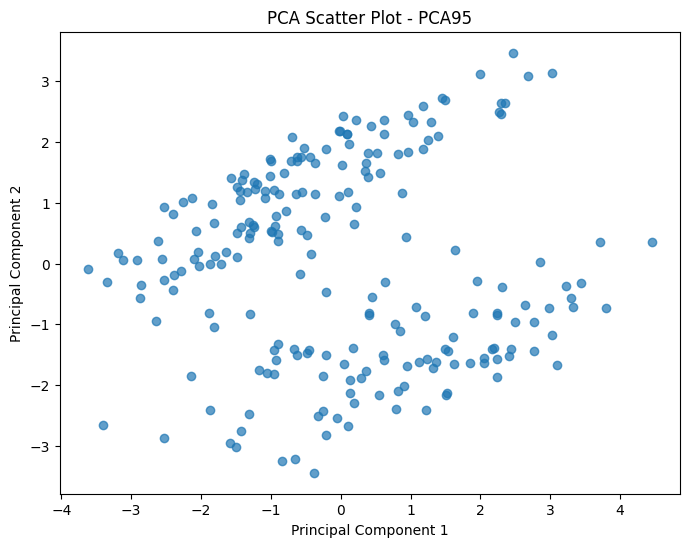

In [27]:
# ------------------------------------------------------------
# 7.1 PCA Scatter Plot
# ------------------------------------------------------------

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

for name, d in datasets.items():

    X = d.values

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(8, 6))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7)

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title(f"PCA Scatter Plot - {name}")

    plt.savefig(FIGURES_DIR / f"10_pca_scatter_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

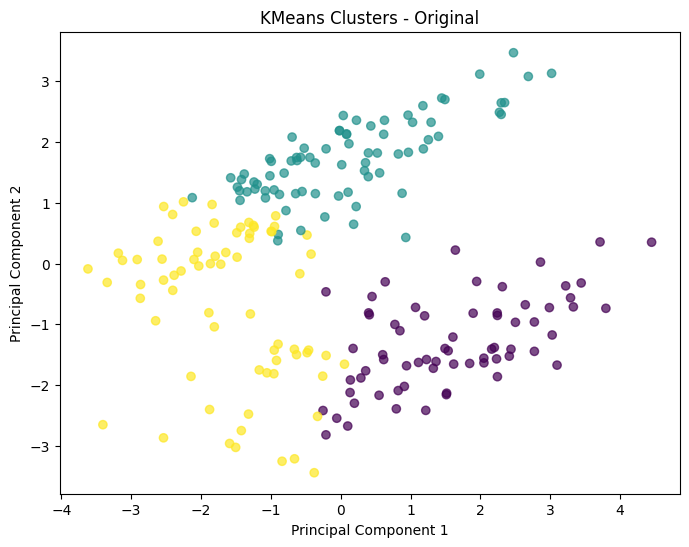

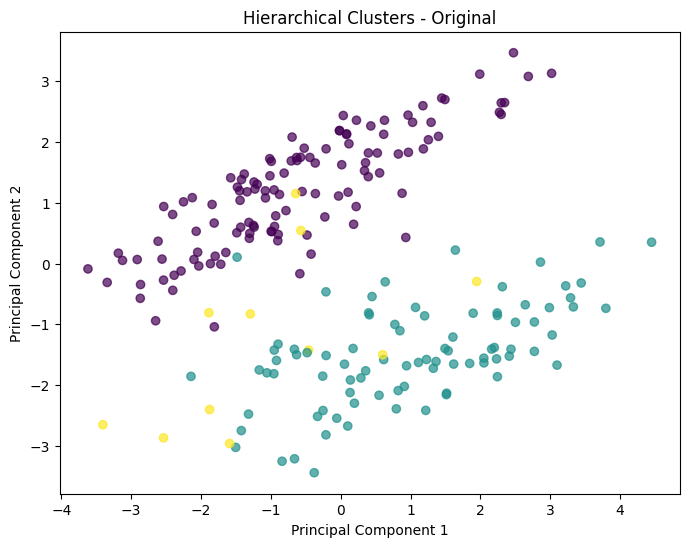

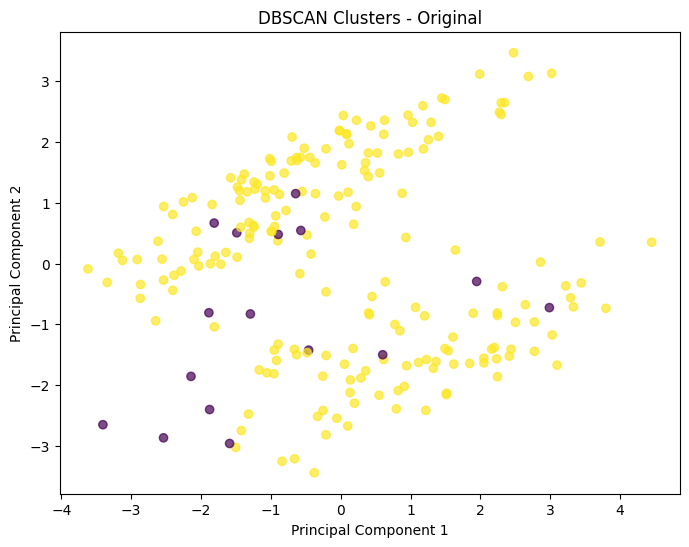

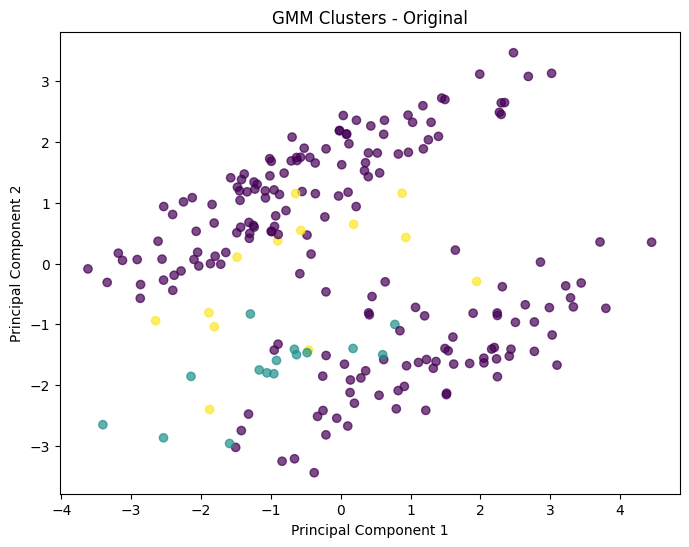

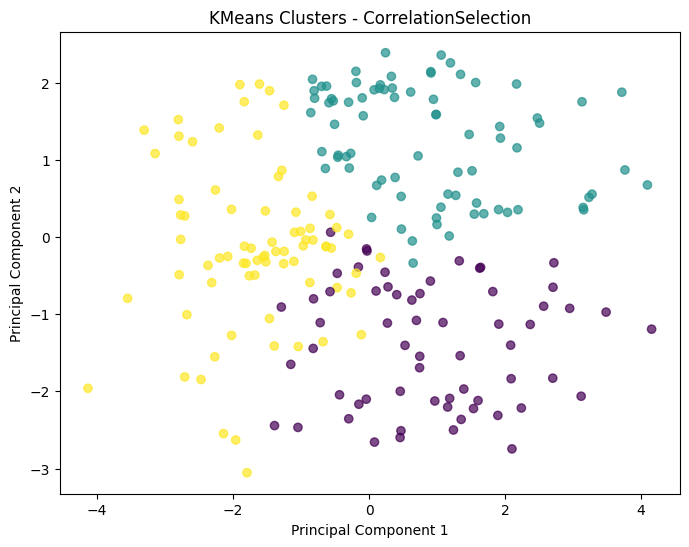

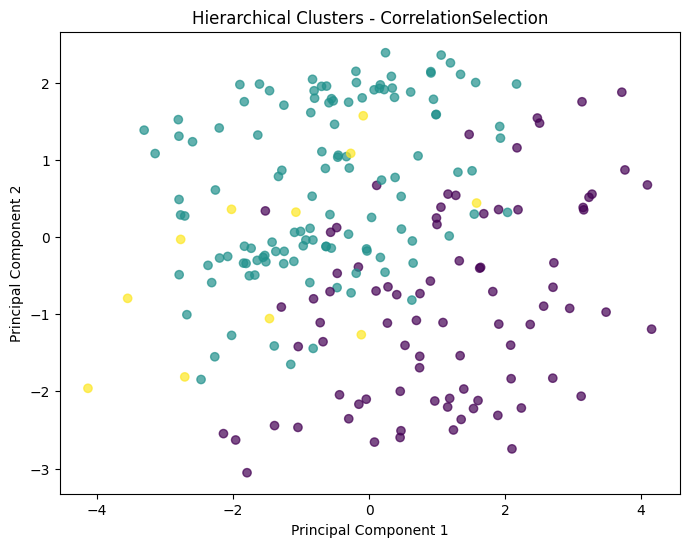

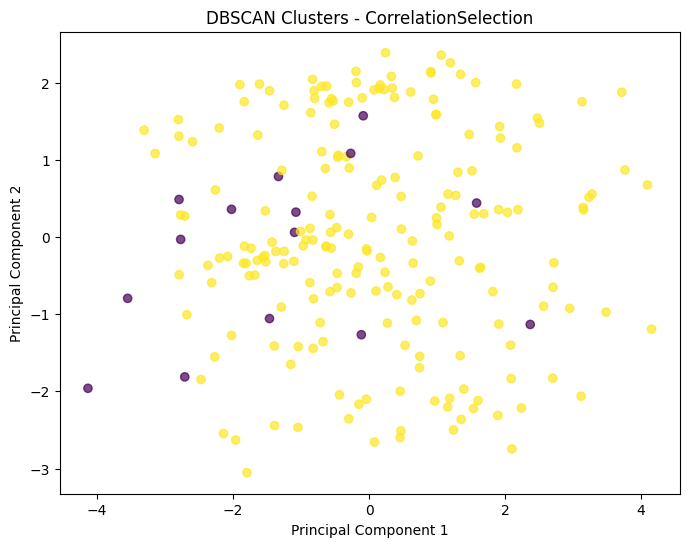

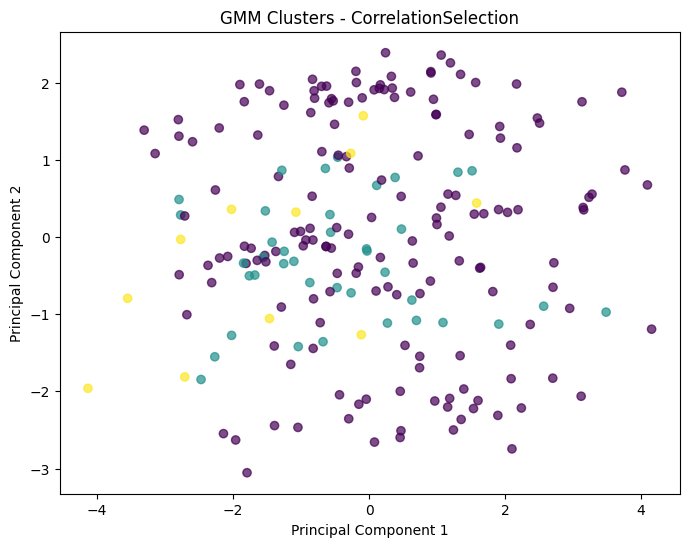

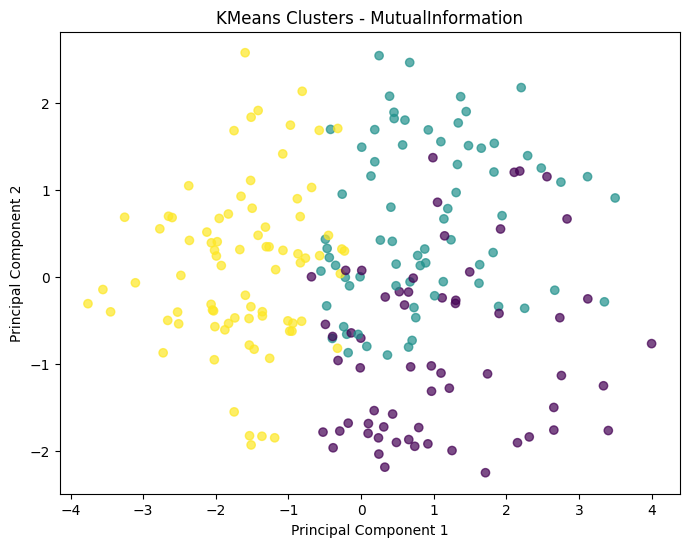

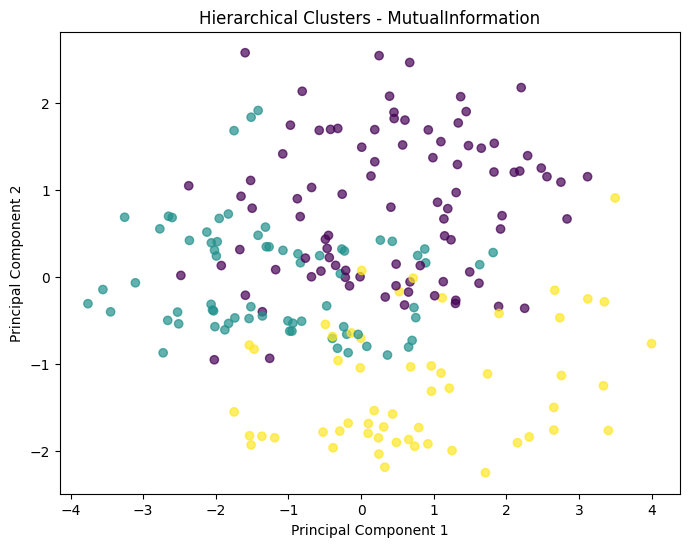

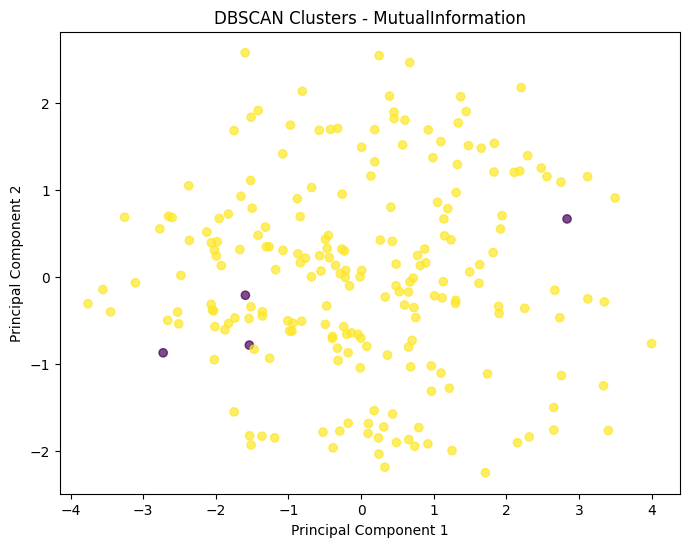

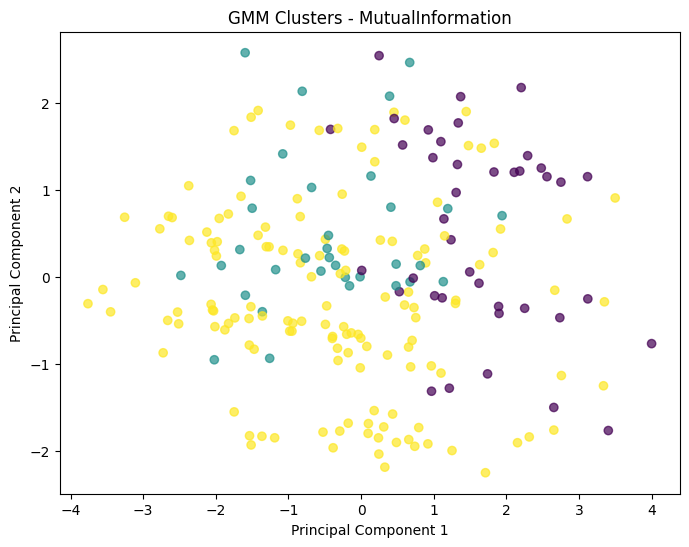

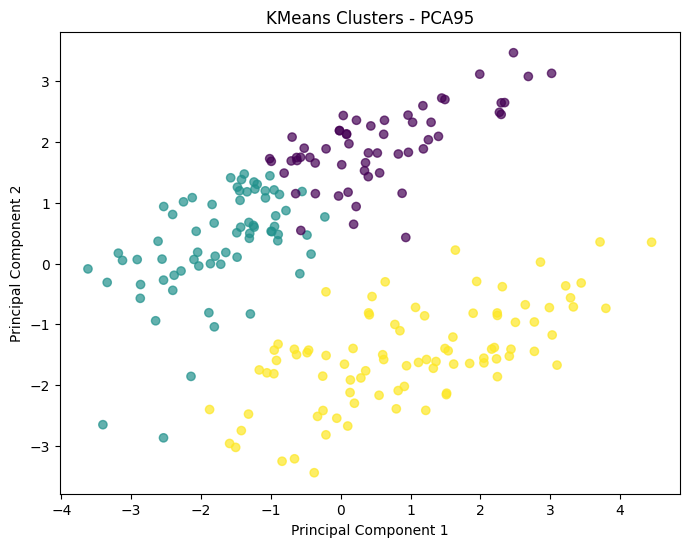

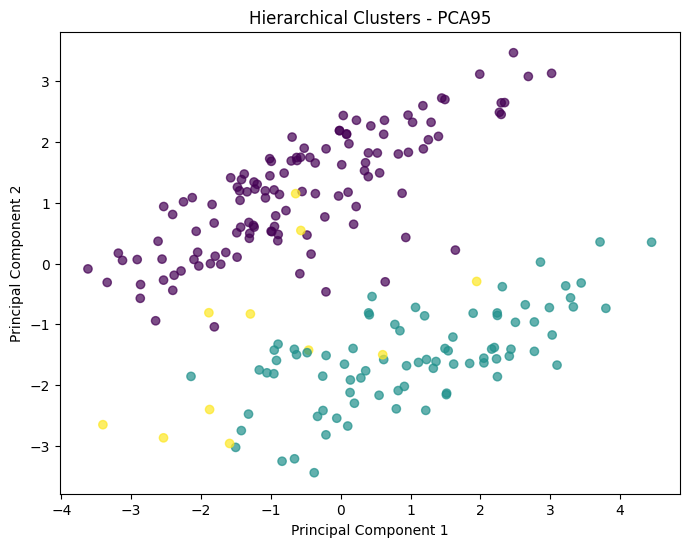

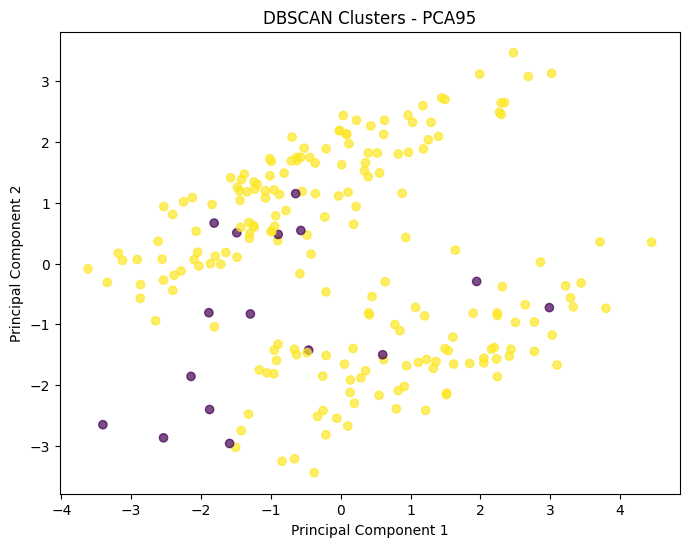

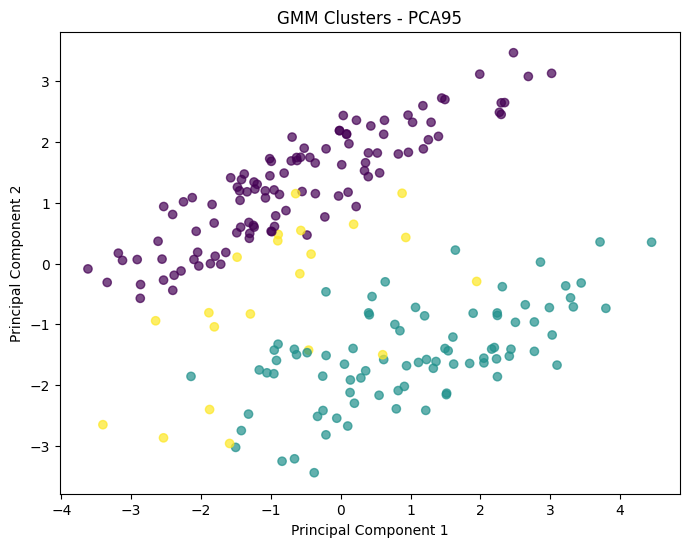

In [28]:
# ------------------------------------------------------------
# 7.2 Cluster Visualization
# ------------------------------------------------------------

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

for name, d in datasets.items():

    X = d.values

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    for algorithm in ["KMeans", "Hierarchical", "DBSCAN", "GMM"]:

        labels = cluster_results[name][algorithm]["labels"]

        plt.figure(figsize=(8, 6))
        plt.scatter(
            X_pca[:, 0],
            X_pca[:, 1],
            c=labels,
            alpha=0.7
        )

        plt.xlabel("Principal Component 1")
        plt.ylabel("Principal Component 2")
        plt.title(f"{algorithm} Clusters - {name}")

        plt.savefig(FIGURES_DIR / f"11_clusters_{algorithm}_{name}.png", dpi=300, bbox_inches="tight")
        plt.show()

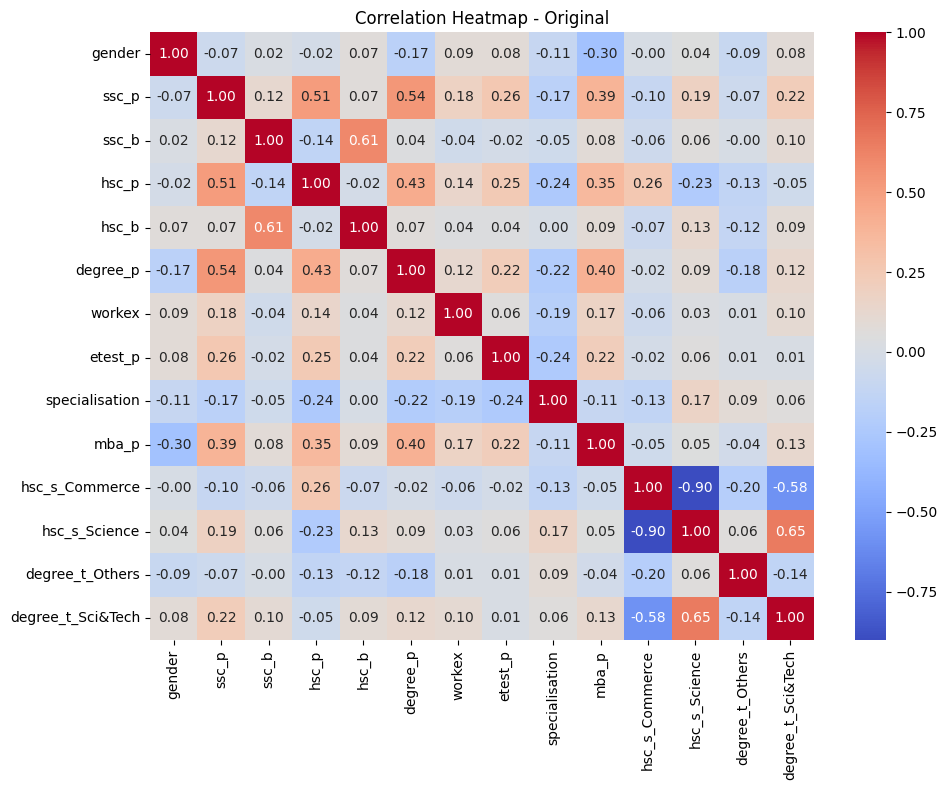

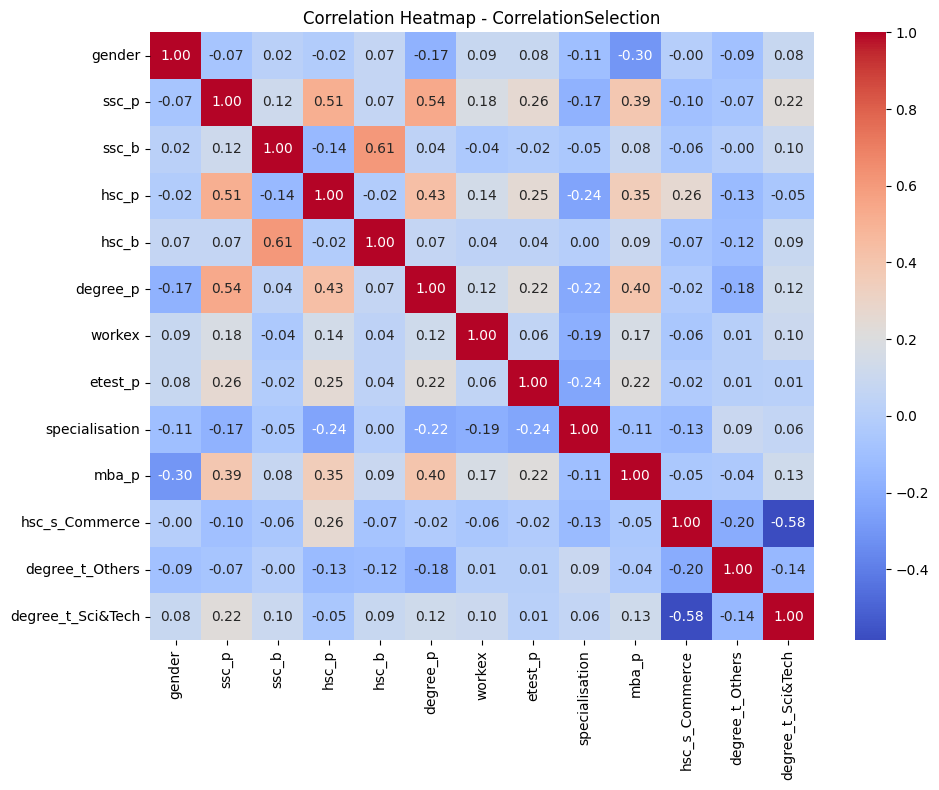

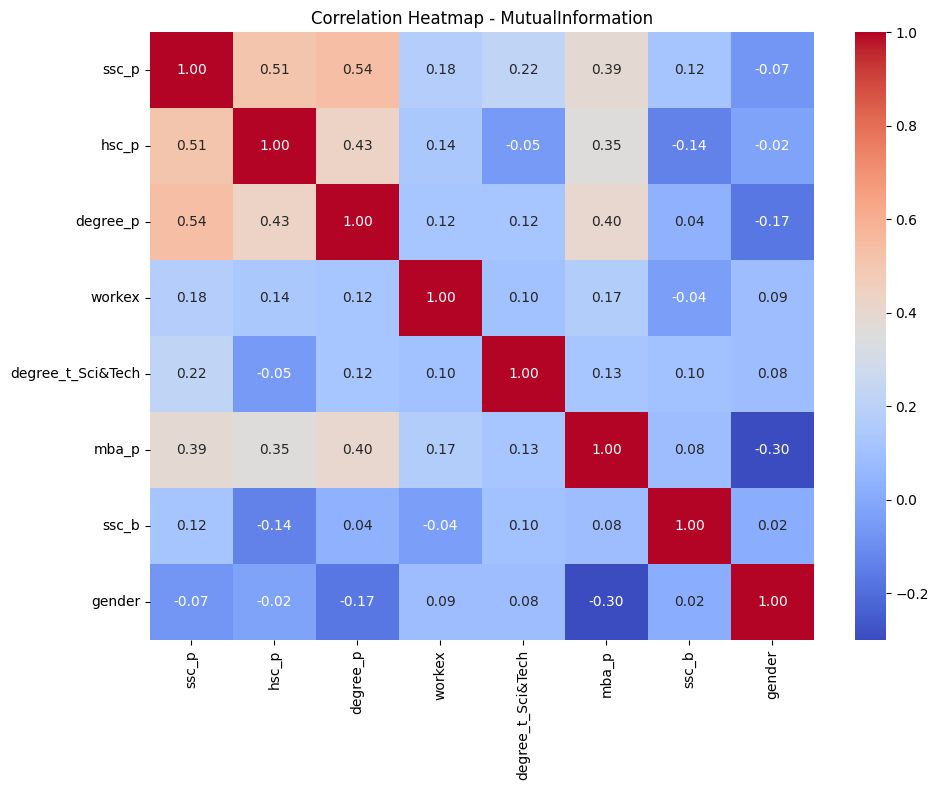

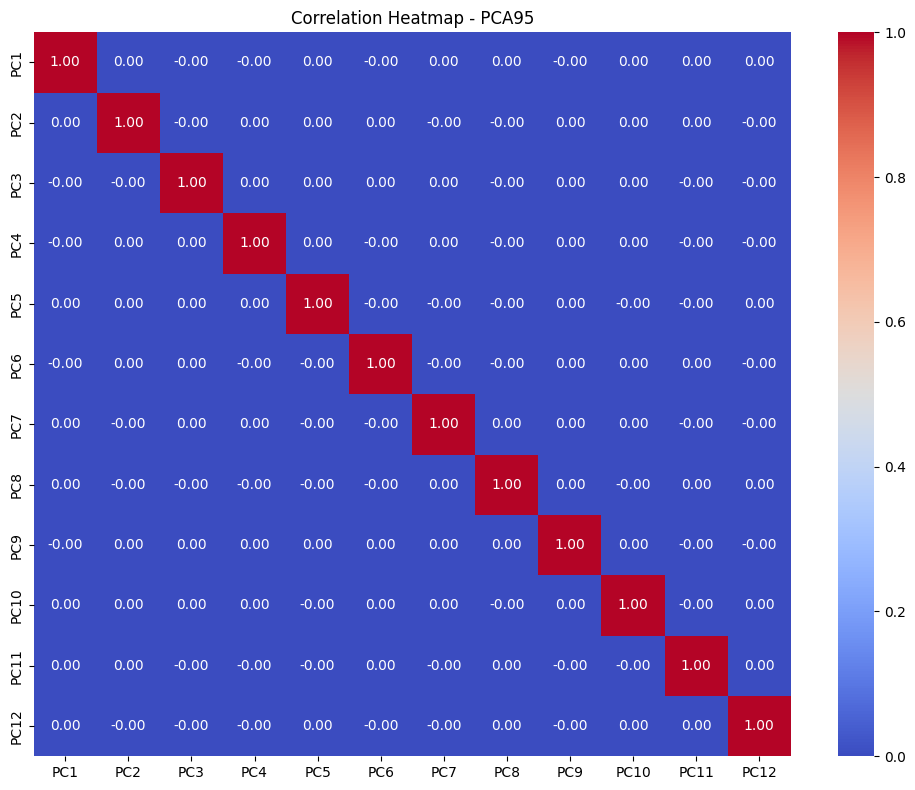

In [29]:
# ------------------------------------------------------------
# 7.3 Heatmap
# ------------------------------------------------------------

import seaborn as sns
import matplotlib.pyplot as plt

for name, d in datasets.items():

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        d.corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm"
    )

    plt.title(f"Correlation Heatmap - {name}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"12_heatmap_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [30]:
# ------------------------------------------------------------
# 7.4 Correlation Matrix
# ------------------------------------------------------------

for name, d in datasets.items():

    correlation_matrix = d.corr()

    print(f"\n================ {name} ================")
    display(correlation_matrix)


================ Original ================


,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,hsc_s_Commerce,hsc_s_Science,degree_t_Others,degree_t_Sci&Tech
gender,1.000000,-0.068969,0.019429,-0.021334,0.065945,-0.173217,0.085153,0.084294,-0.106160,-0.300531,-0.001087,0.042682,-0.093246,0.084072
ssc_p,-0.068969,1.000000,0.116194,0.511472,0.066996,0.538404,0.175675,0.261993,-0.172536,0.388478,-0.101323,0.189847,-0.066127,0.221235
ssc_b,0.019429,0.116194,1.000000,-0.137013,0.605883,0.038070,-0.040744,-0.018991,-0.051565,0.083120,-0.056671,0.058505,-0.002758,0.101060
hsc_p,-0.021334,0.511472,-0.137013,1.000000,-0.019548,0.434206,0.141025,0.245113,-0.241630,0.354823,0.258093,-0.226675,-0.131382,-0.053599
hsc_b,0.065945,0.066996,0.605883,-0.019548,1.000000,0.067229,0.038357,0.039108,0.002232,0.090201,-0.073522,0.126446,-0.116920,0.086548
degree_p,-0.173217,0.538404,0.038070,0.434206,0.067229,1.000000,0.122648,0.224470,-0.218286,0.402364,-0.022724,0.092006,-0.180408,0.123477
workex,0.085153,0.175675,-0.040744,0.141025,0.038357,0.122648,1.000000,0.056735,-0.191174,0.168811,-0.056719,0.033270,0.009507,0.102962
etest_p,0.084294,0.261993,-0.018991,0.245113,0.039108,0.224470,0.056735,1.000000,-0.236315,0.218055,-0.021732,0.055352,0.006907,0.009748
specialisation,-0.106160,-0.172536,-0.051565,-0.241630,0.002232,-0.218286,-0.191174,-0.236315,1.000000,-0.105728,-0.129985,0.166639,0.090948,0.061503
mba_p,-0.300531,0.388478,0.083120,0.354823,0.090201,0.402364,0.168811,0.218055,-0.105728,1.000000,-0.049415,0.048050,-0.036055,0.125009



================ CorrelationSelection ================


,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,hsc_s_Commerce,degree_t_Others,degree_t_Sci&Tech
gender,1.000000,-0.068969,0.019429,-0.021334,0.065945,-0.173217,0.085153,0.084294,-0.106160,-0.300531,-0.001087,-0.093246,0.084072
ssc_p,-0.068969,1.000000,0.116194,0.511472,0.066996,0.538404,0.175675,0.261993,-0.172536,0.388478,-0.101323,-0.066127,0.221235
ssc_b,0.019429,0.116194,1.000000,-0.137013,0.605883,0.038070,-0.040744,-0.018991,-0.051565,0.083120,-0.056671,-0.002758,0.101060
hsc_p,-0.021334,0.511472,-0.137013,1.000000,-0.019548,0.434206,0.141025,0.245113,-0.241630,0.354823,0.258093,-0.131382,-0.053599
hsc_b,0.065945,0.066996,0.605883,-0.019548,1.000000,0.067229,0.038357,0.039108,0.002232,0.090201,-0.073522,-0.116920,0.086548
degree_p,-0.173217,0.538404,0.038070,0.434206,0.067229,1.000000,0.122648,0.224470,-0.218286,0.402364,-0.022724,-0.180408,0.123477
workex,0.085153,0.175675,-0.040744,0.141025,0.038357,0.122648,1.000000,0.056735,-0.191174,0.168811,-0.056719,0.009507,0.102962
etest_p,0.084294,0.261993,-0.018991,0.245113,0.039108,0.224470,0.056735,1.000000,-0.236315,0.218055,-0.021732,0.006907,0.009748
specialisation,-0.106160,-0.172536,-0.051565,-0.241630,0.002232,-0.218286,-0.191174,-0.236315,1.000000,-0.105728,-0.129985,0.090948,0.061503
mba_p,-0.300531,0.388478,0.083120,0.354823,0.090201,0.402364,0.168811,0.218055,-0.105728,1.000000,-0.049415,-0.036055,0.125009



================ MutualInformation ================


,ssc_p,hsc_p,degree_p,workex,degree_t_Sci&Tech,mba_p,ssc_b,gender
ssc_p,1.000000,0.511472,0.538404,0.175675,0.221235,0.388478,0.116194,-0.068969
hsc_p,0.511472,1.000000,0.434206,0.141025,-0.053599,0.354823,-0.137013,-0.021334
degree_p,0.538404,0.434206,1.000000,0.122648,0.123477,0.402364,0.038070,-0.173217
workex,0.175675,0.141025,0.122648,1.000000,0.102962,0.168811,-0.040744,0.085153
degree_t_Sci&Tech,0.221235,-0.053599,0.123477,0.102962,1.000000,0.125009,0.101060,0.084072
mba_p,0.388478,0.354823,0.402364,0.168811,0.125009,1.000000,0.083120,-0.300531
ssc_b,0.116194,-0.137013,0.038070,-0.040744,0.101060,0.083120,1.000000,0.019429
gender,-0.068969,-0.021334,-0.173217,0.085153,0.084072,-0.300531,0.019429,1.000000



================ PCA95 ================


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
PC1,1.000000e+00,8.657681e-17,-2.712228e-16,-3.418206e-16,2.310339e-16,-3.583968e-16,2.660277e-16,8.199617e-17,-3.104942e-17,1.008158e-16,1.018449e-16,1.109647e-16
PC2,8.657681e-17,1.000000e+00,-1.791686e-16,1.979505e-16,7.484921e-17,1.314941e-16,-1.067711e-16,-1.140237e-16,1.296041e-16,4.585233e-17,4.868170e-16,-4.267265e-17
PC3,-2.712228e-16,-1.791686e-16,1.000000e+00,7.821233e-16,2.485871e-16,2.902326e-16,1.053740e-16,-2.539133e-16,2.901145e-16,3.965342e-16,-1.145498e-16,-3.128223e-16
PC4,-3.418206e-16,1.979505e-16,7.821233e-16,1.000000e+00,3.582398e-16,-6.271846e-16,1.172806e-15,-4.020907e-16,1.011329e-15,1.653107e-15,-1.126848e-15,-4.563529e-16
PC5,2.310339e-16,7.484921e-17,2.485871e-16,3.582398e-16,1.000000e+00,-5.116227e-16,-4.686524e-17,-2.865731e-16,3.747398e-16,-3.698858e-16,-1.718947e-16,3.579488e-16
PC6,-3.583968e-16,1.314941e-16,2.902326e-16,-6.271846e-16,-5.116227e-16,1.000000e+00,-8.449397e-16,-1.851375e-16,9.606427e-17,6.356187e-17,1.066062e-16,-2.387575e-16
PC7,2.660277e-16,-1.067711e-16,1.053740e-16,1.172806e-15,-4.686524e-17,-8.449397e-16,1.000000e+00,4.673072e-16,5.117545e-16,1.603591e-15,-8.007164e-16,-6.840432e-16
PC8,8.199617e-17,-1.140237e-16,-2.539133e-16,-4.020907e-16,-2.865731e-16,-1.851375e-16,4.673072e-16,1.000000e+00,4.192028e-17,-6.738029e-16,3.552690e-16,2.029767e-17
PC9,-3.104942e-17,1.296041e-16,2.901145e-16,1.011329e-15,3.747398e-16,9.606427e-17,5.117545e-16,4.192028e-17,1.000000e+00,6.008120e-16,-6.205285e-16,-1.988735e-15
PC10,1.008158e-16,4.585233e-17,3.965342e-16,1.653107e-15,-3.698858e-16,6.356187e-17,1.603591e-15,-6.738029e-16,6.008120e-16,1.000000e+00,-1.115244e-15,9.310710e-16


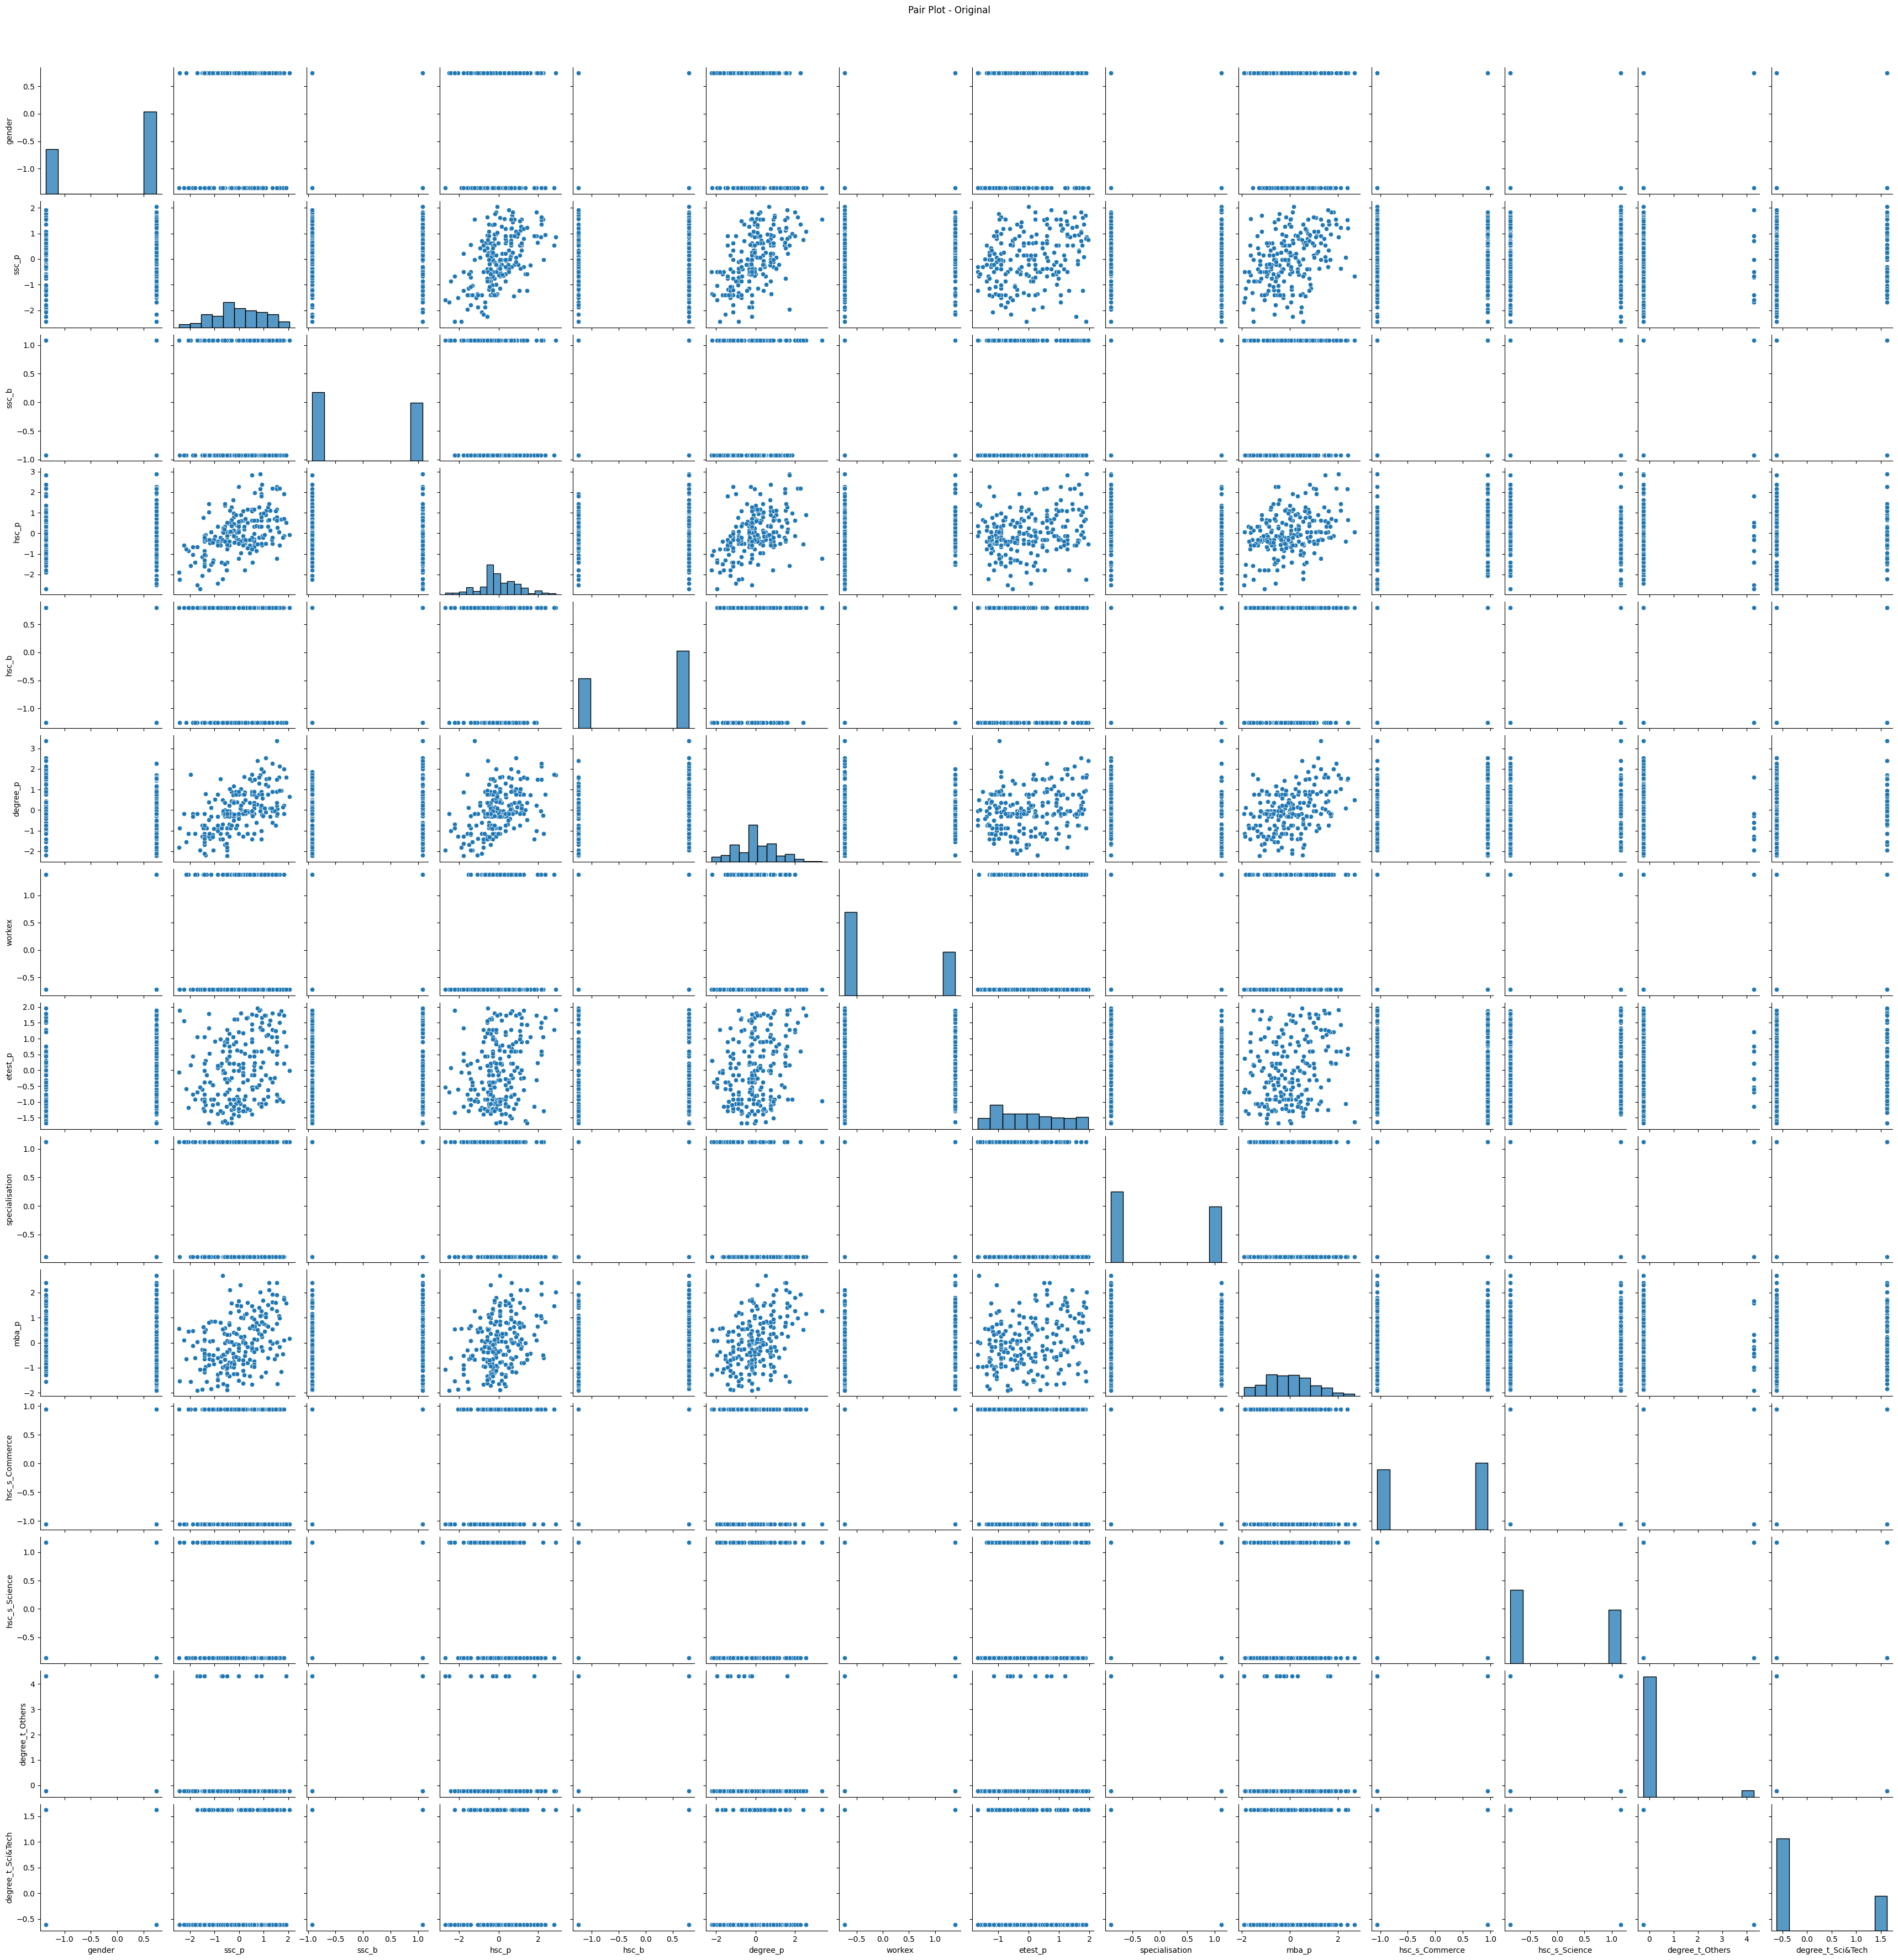

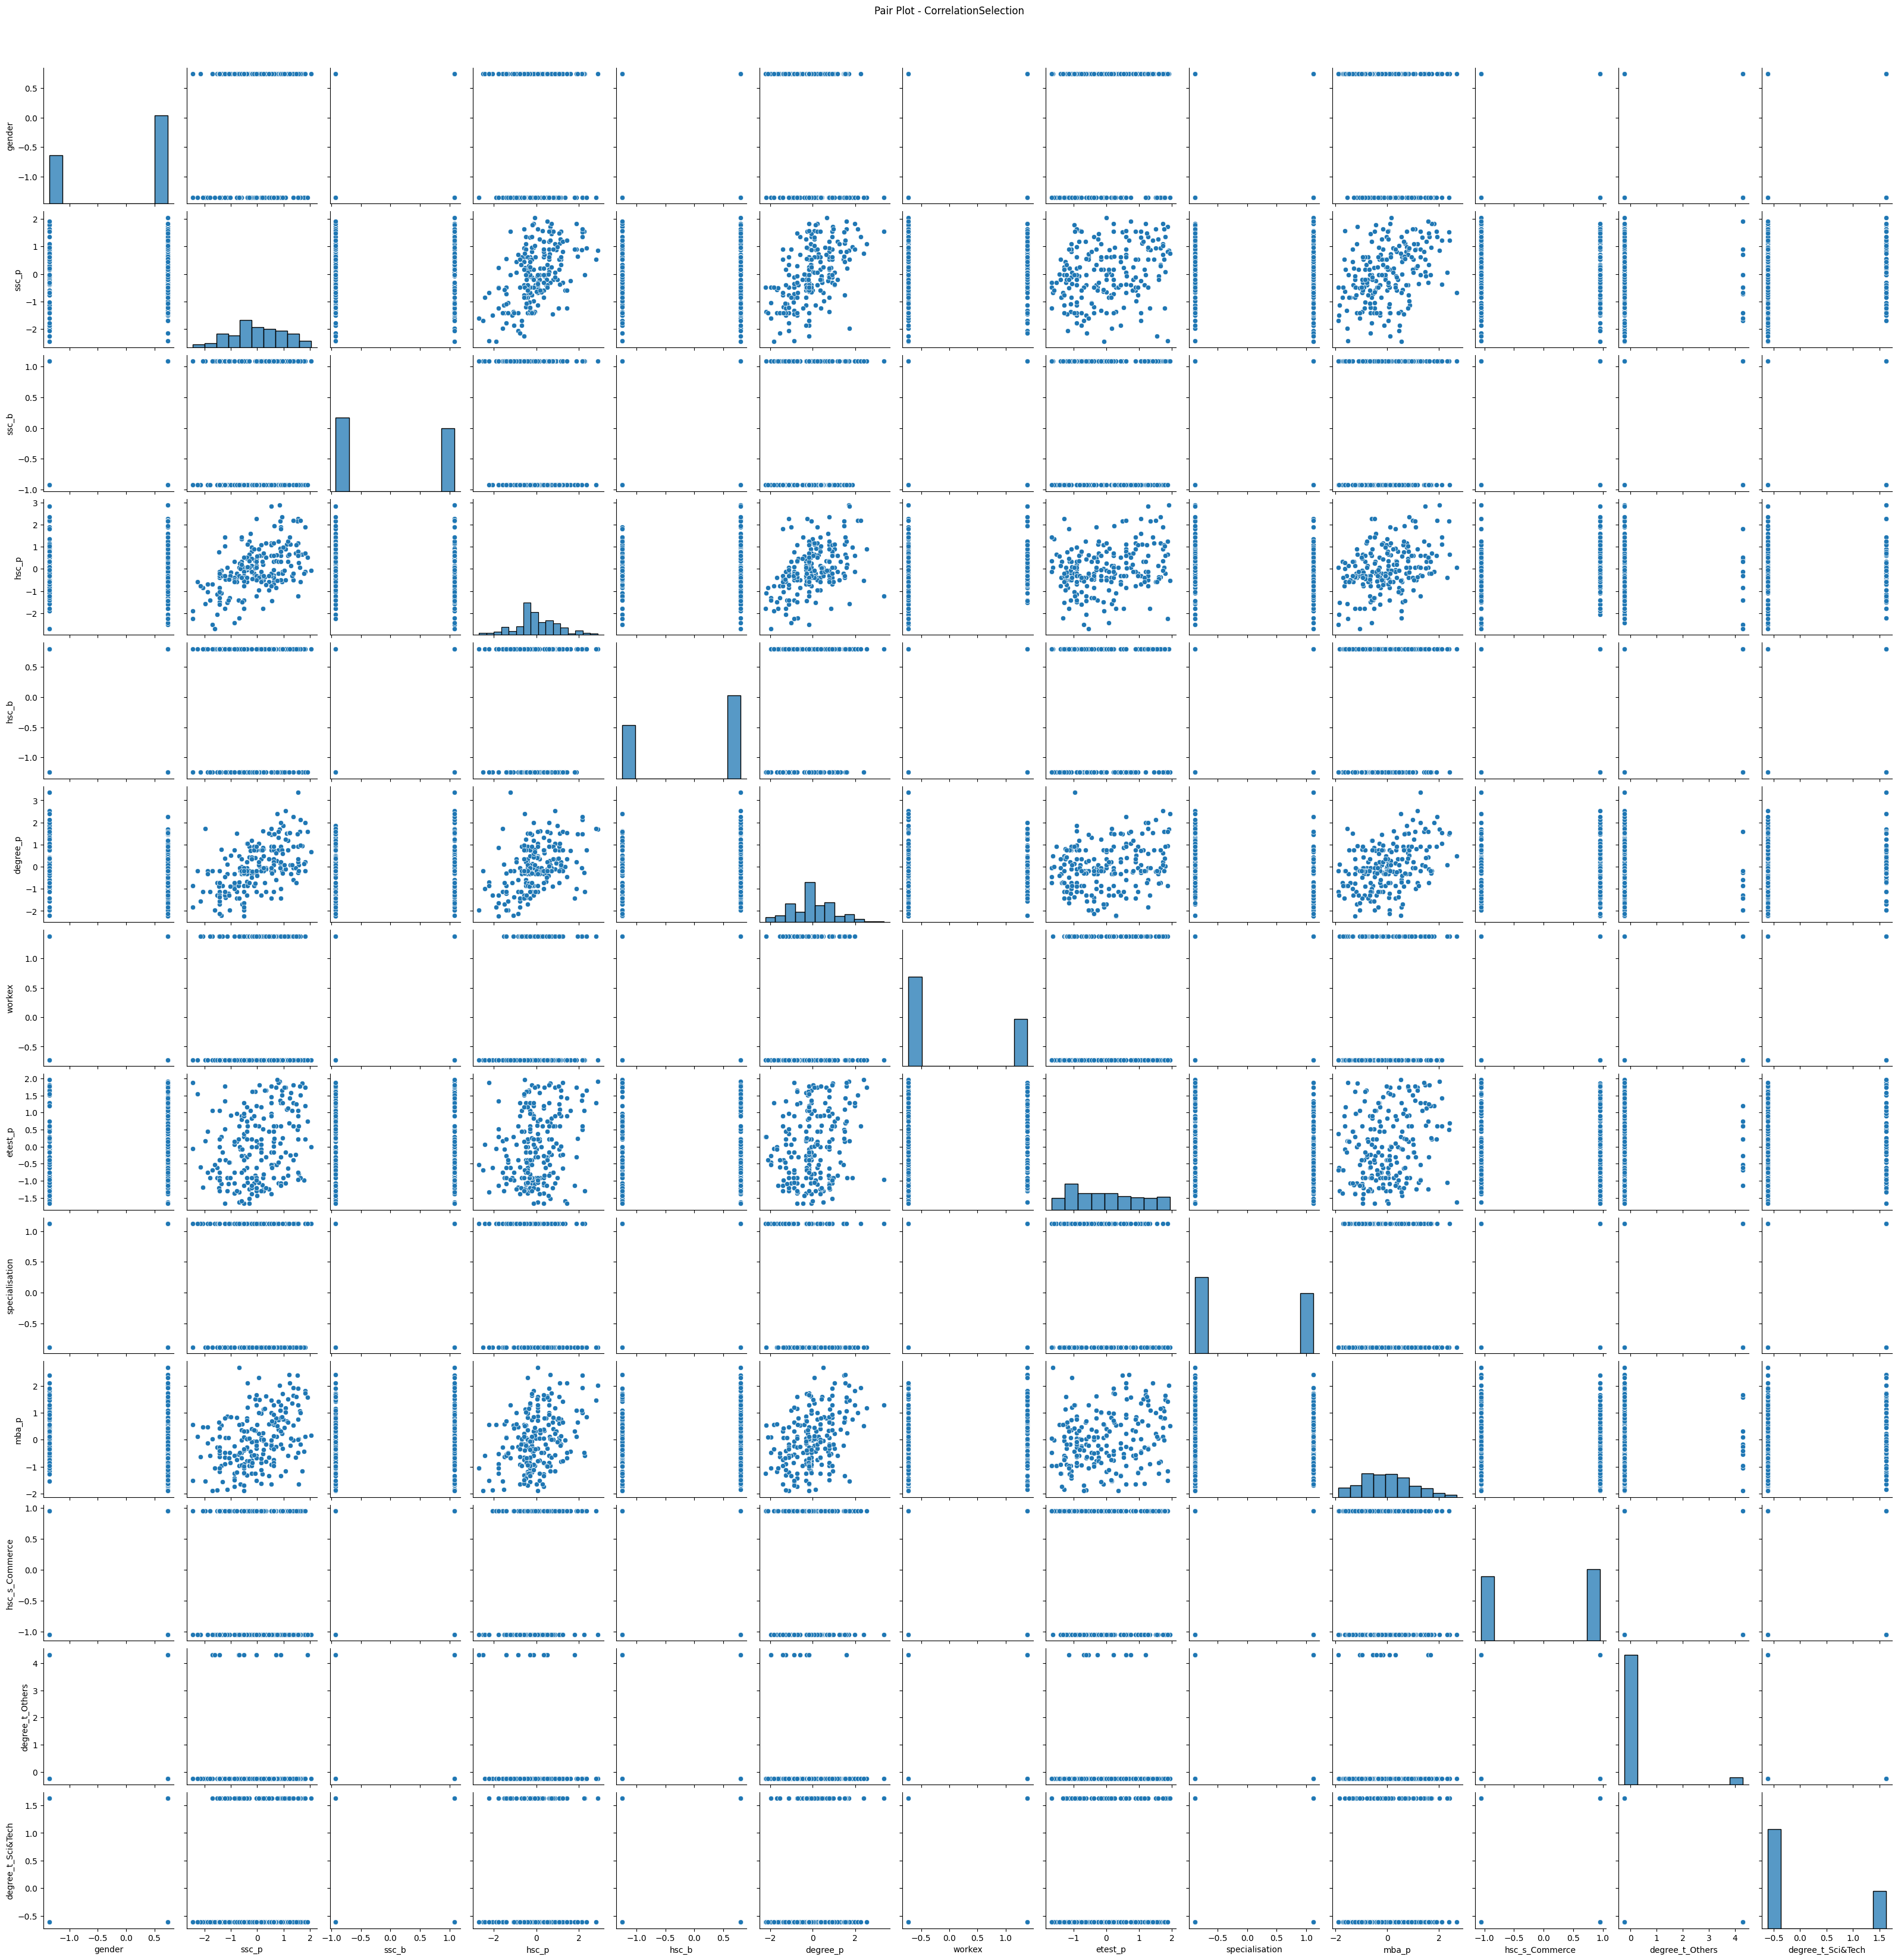

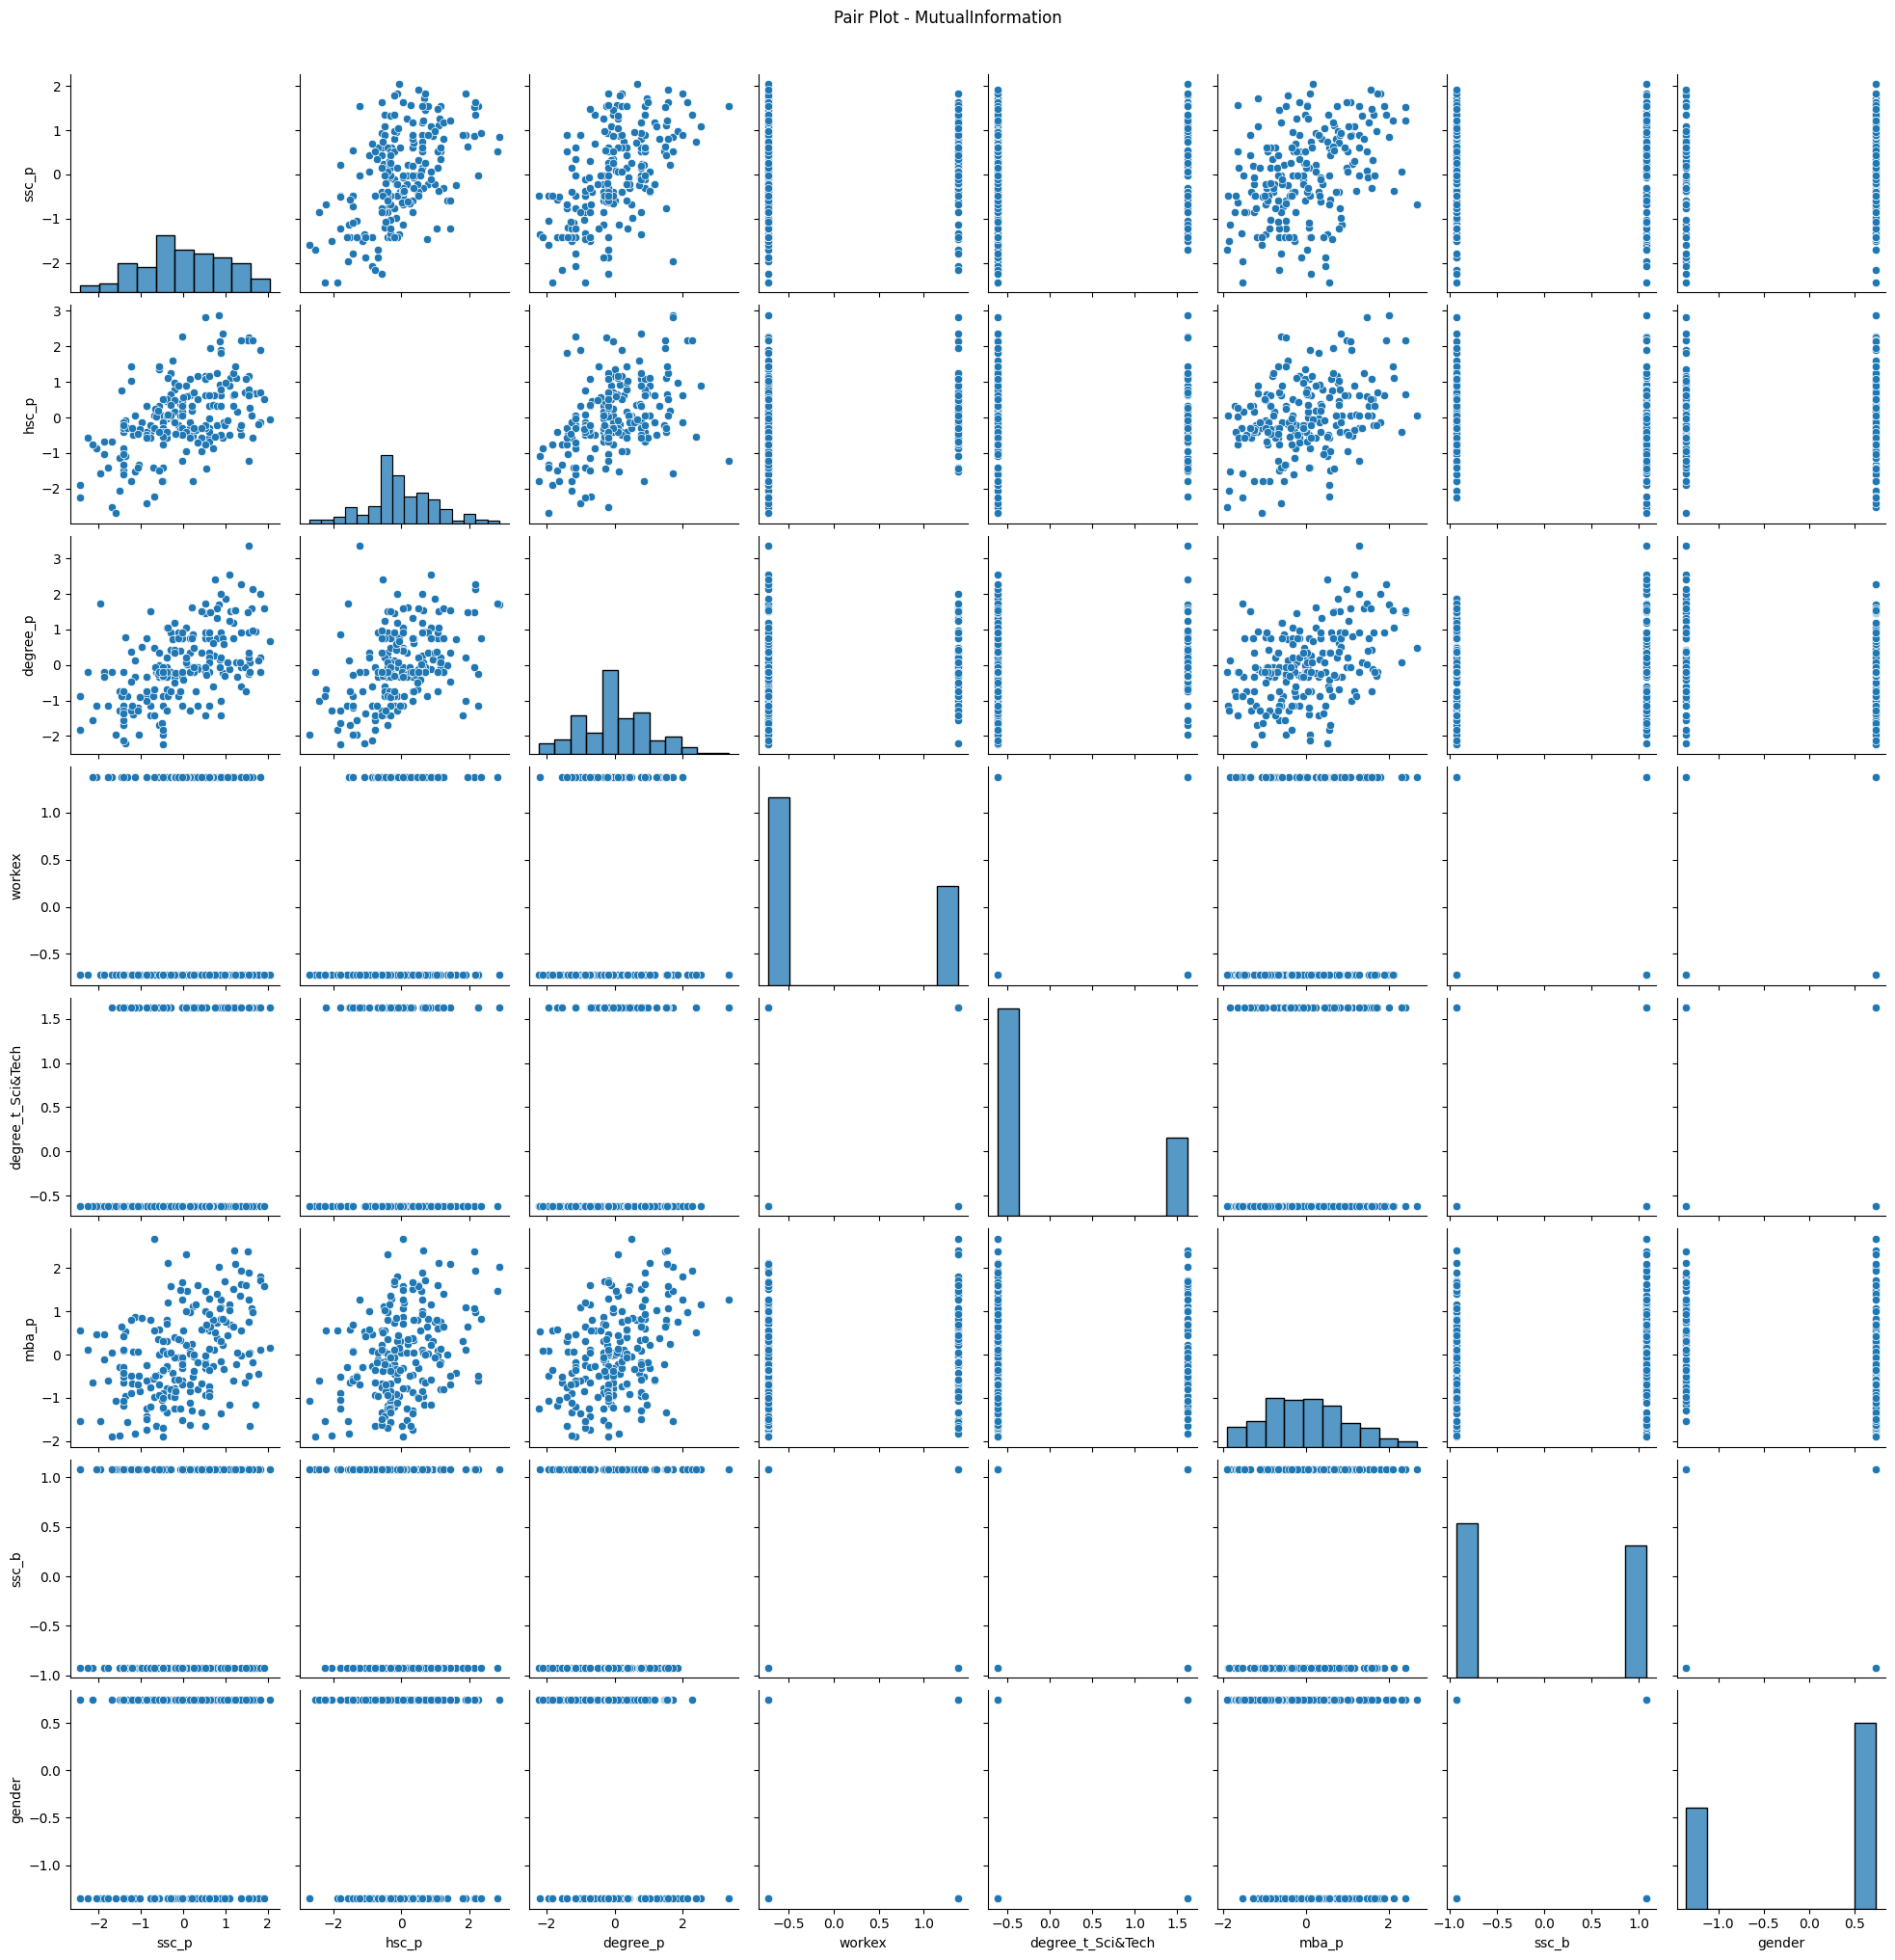

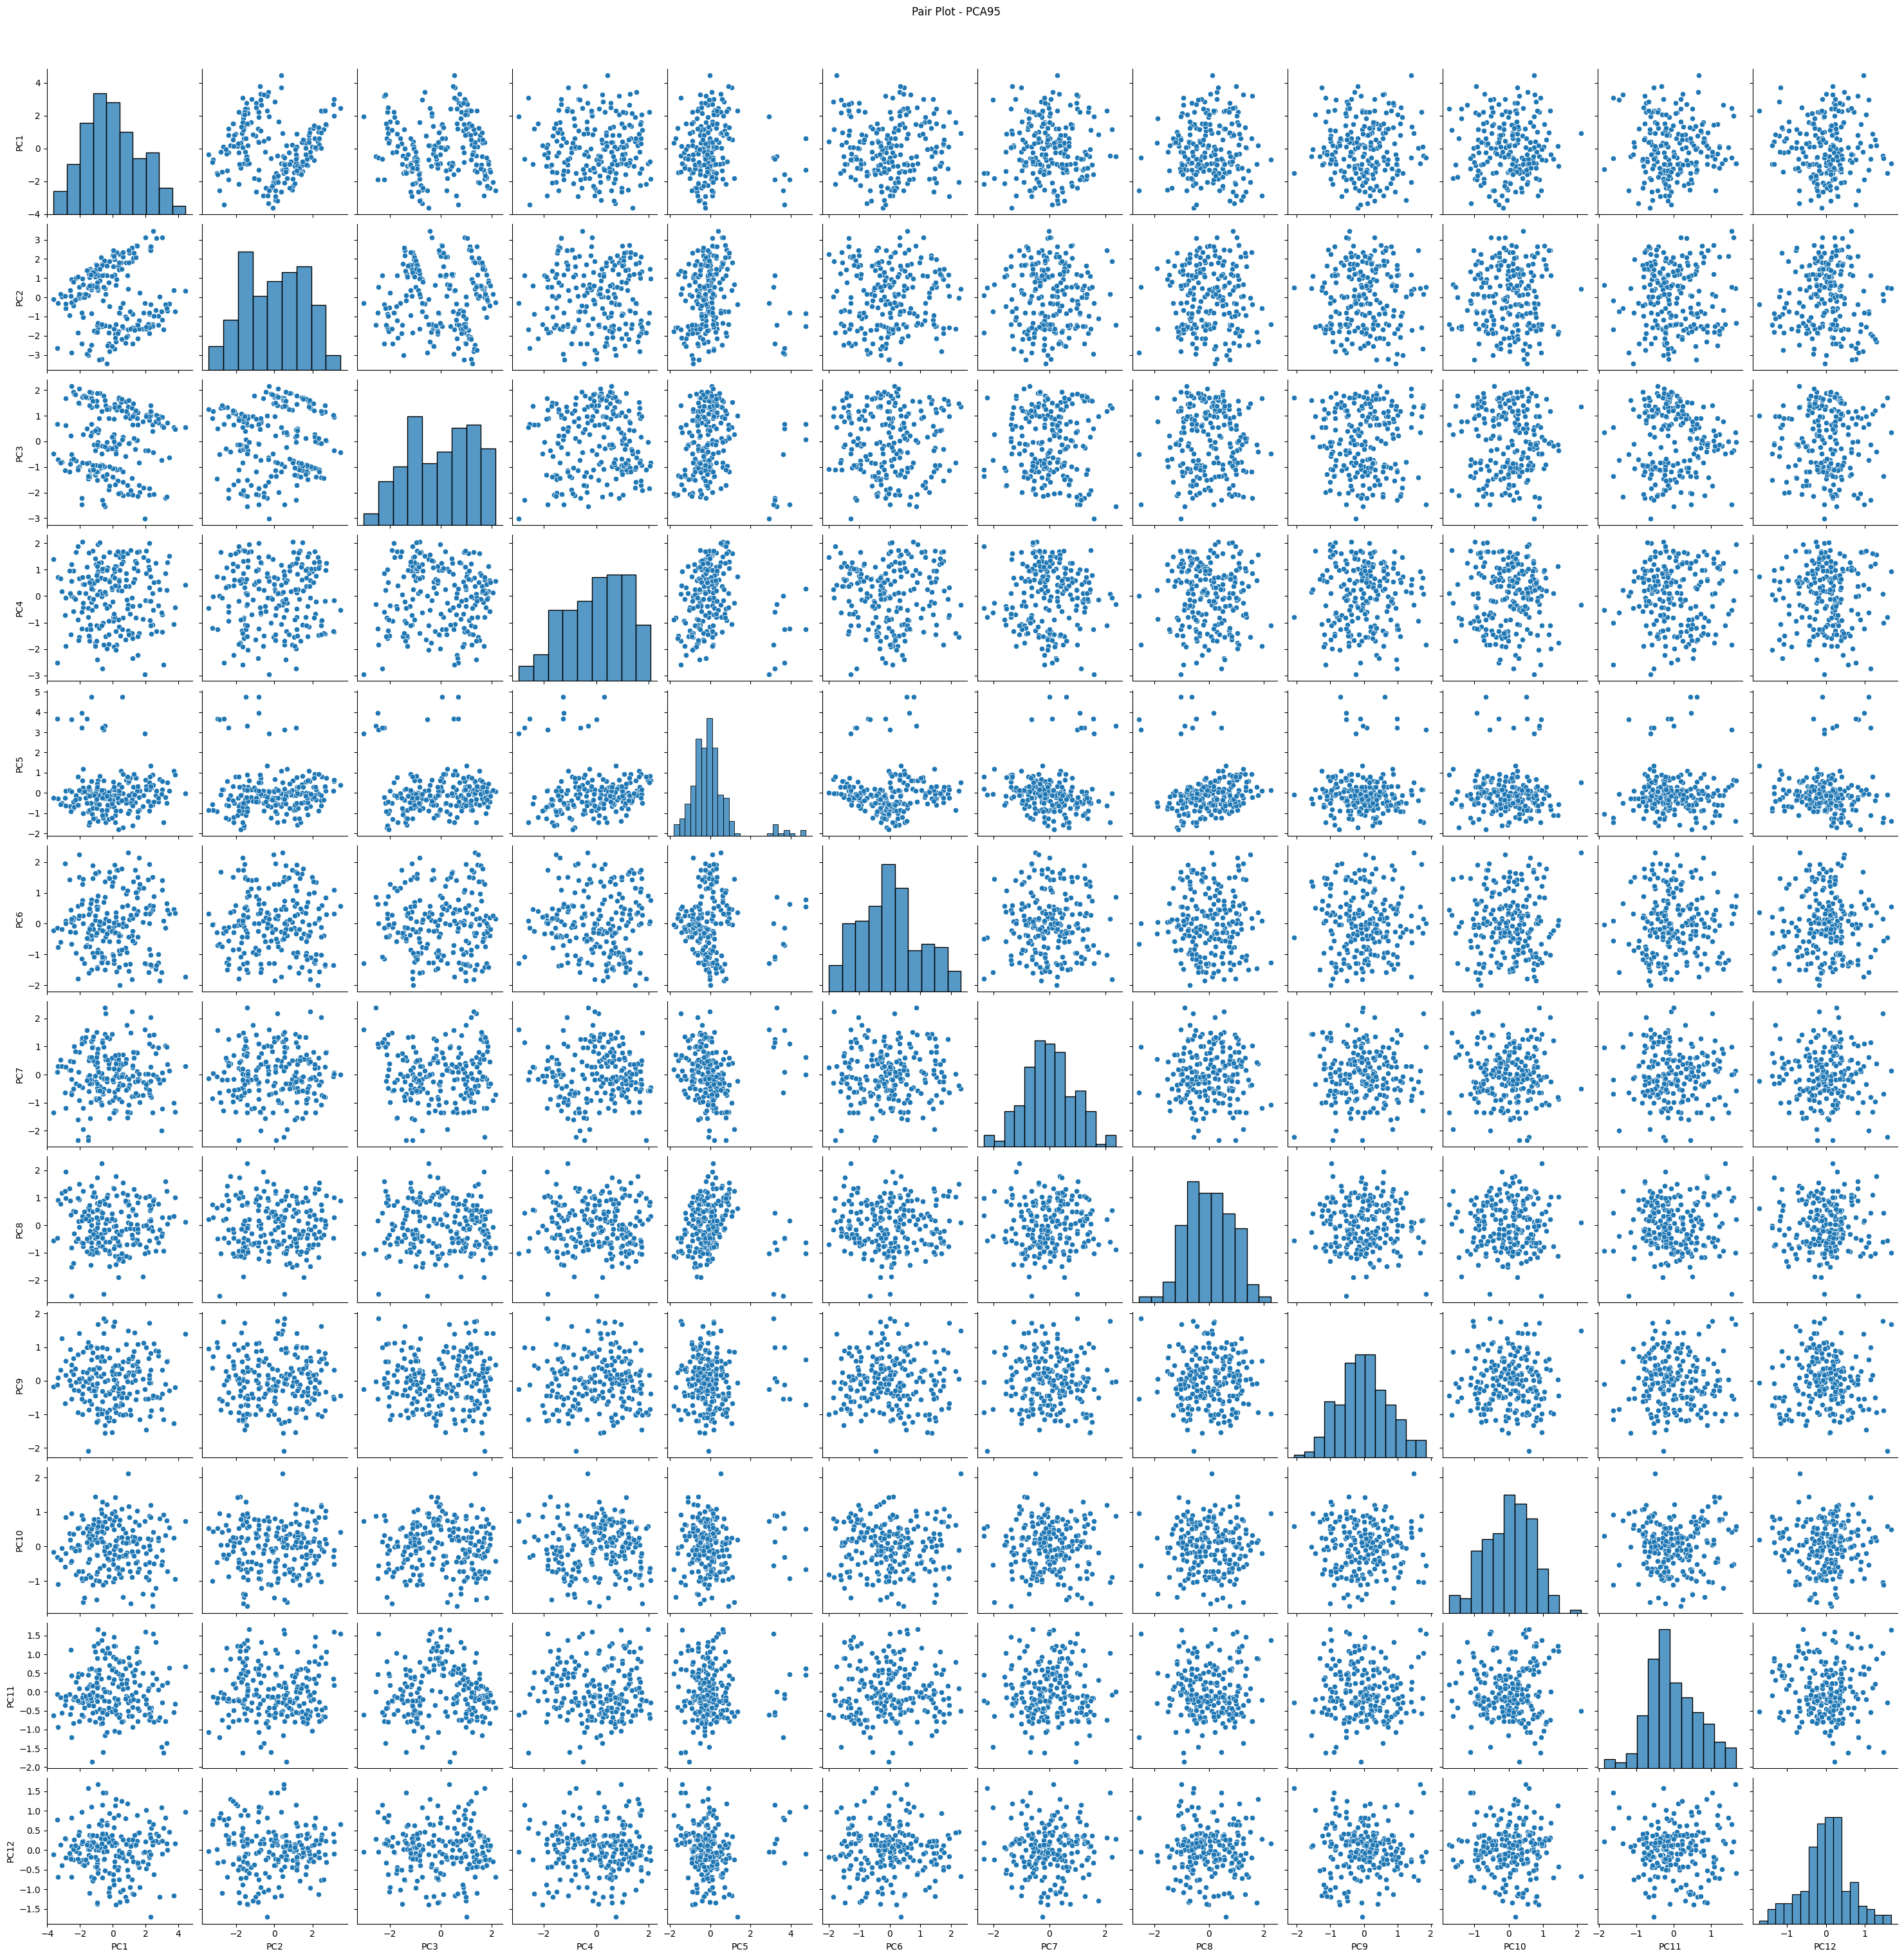

In [31]:
# ------------------------------------------------------------
# 7.5 Pair Plot
# ------------------------------------------------------------

for name, d in datasets.items():

    sns.pairplot(d)

    plt.suptitle(
        f"Pair Plot - {name}",
        y=1.02
    )

    plt.savefig(FIGURES_DIR / f"13_pairplot_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

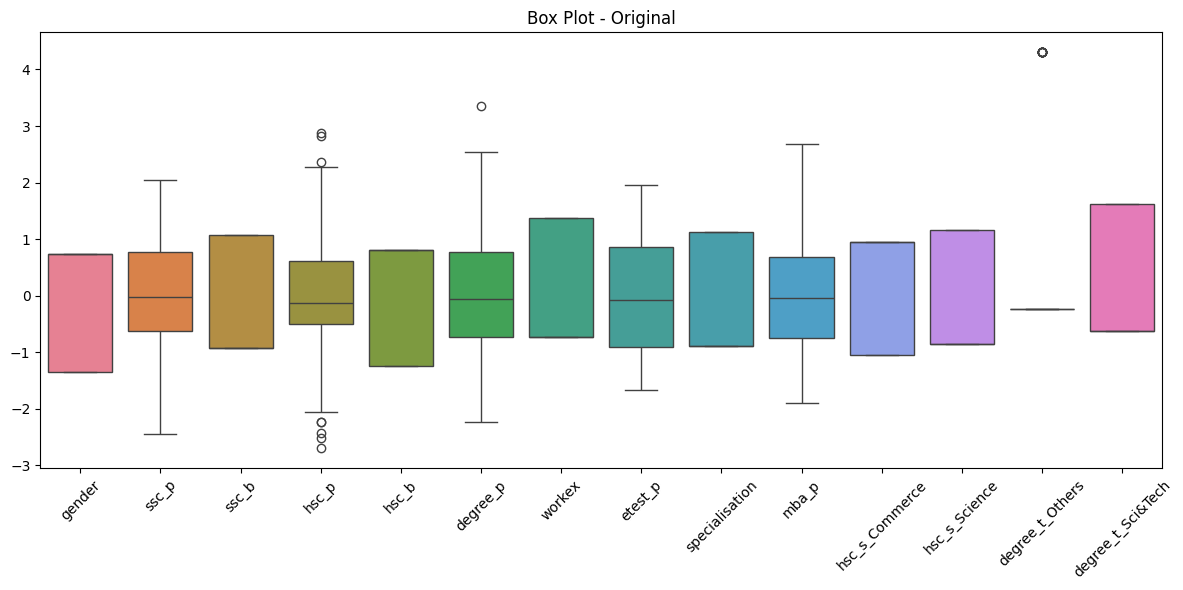

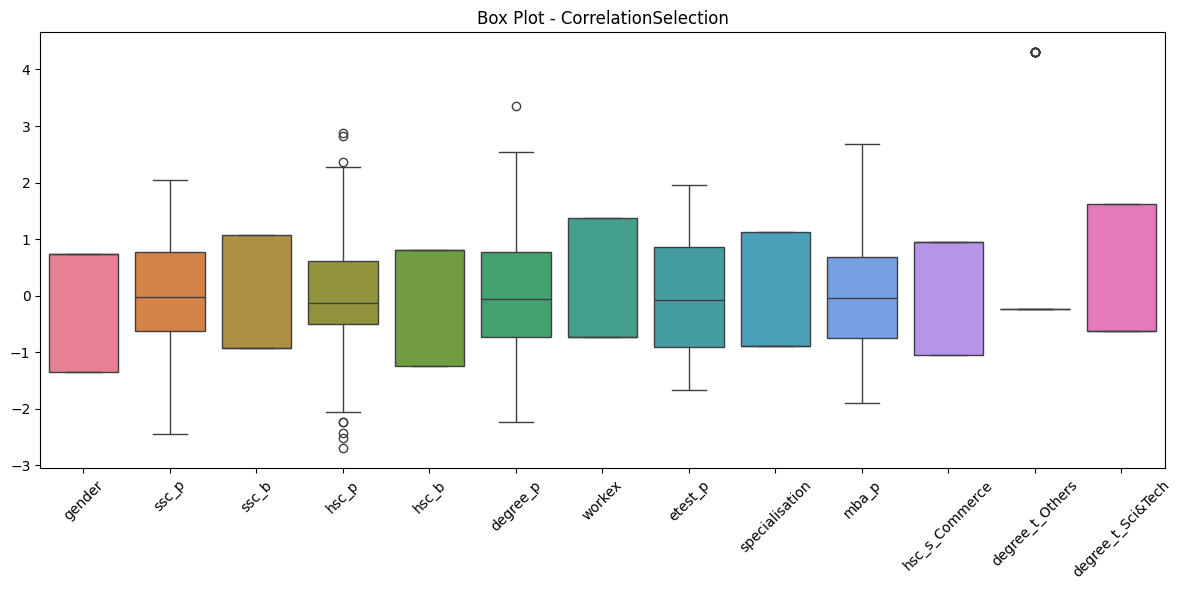

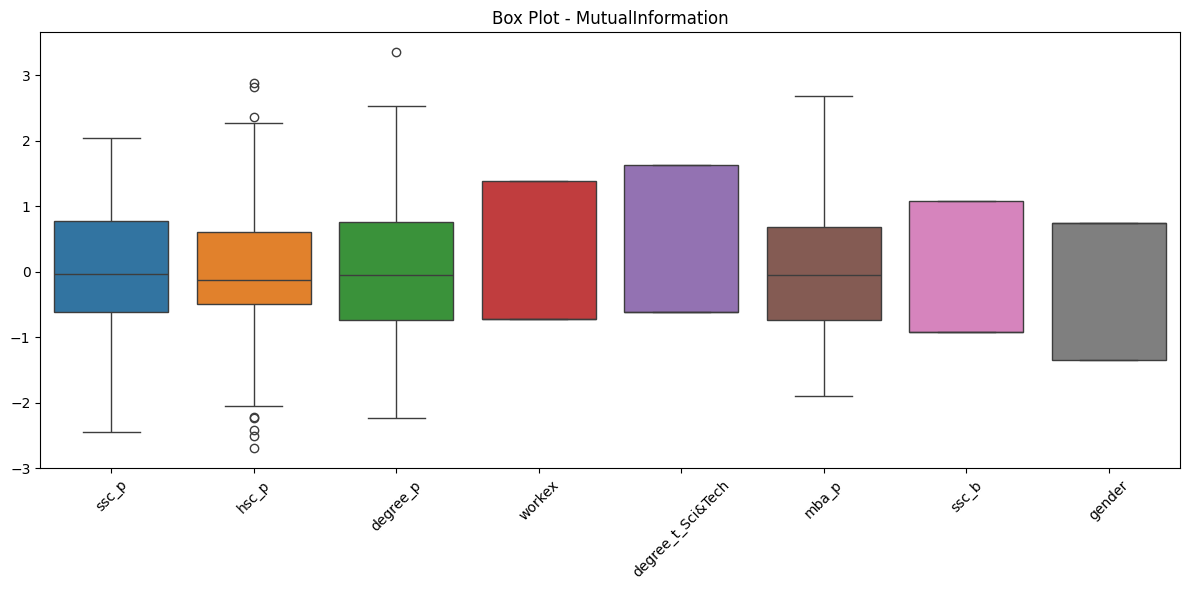

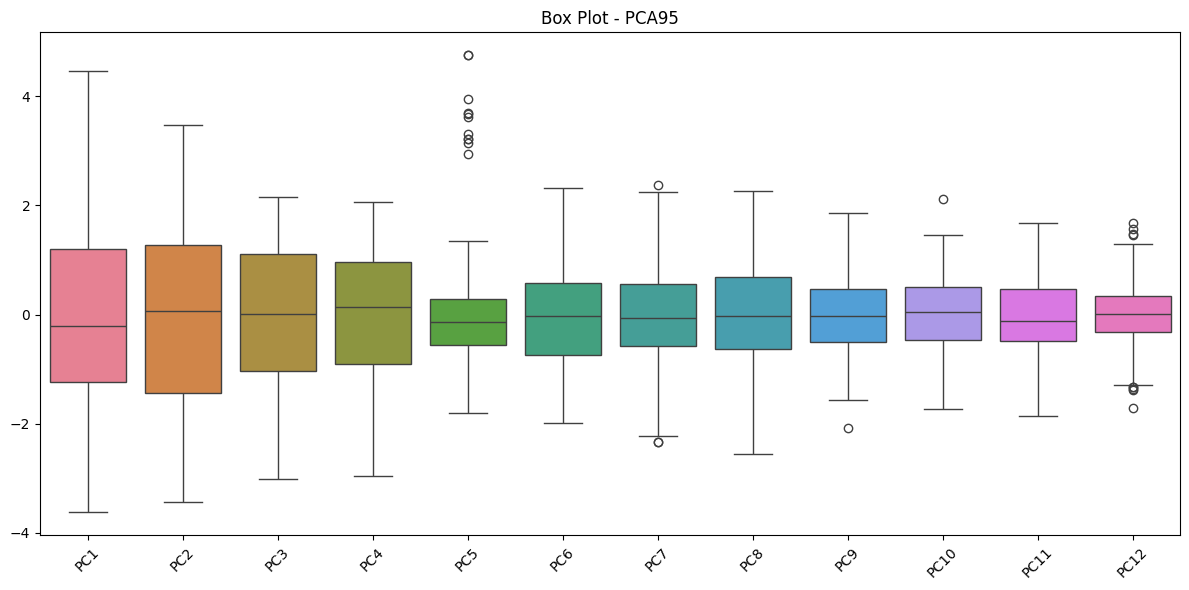

In [32]:
# ------------------------------------------------------------
# 7.6 Box Plot
# ------------------------------------------------------------

for name, d in datasets.items():

    plt.figure(figsize=(12, 6))

    sns.boxplot(data=d)

    plt.title(f"Box Plot - {name}")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"14_boxplot_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

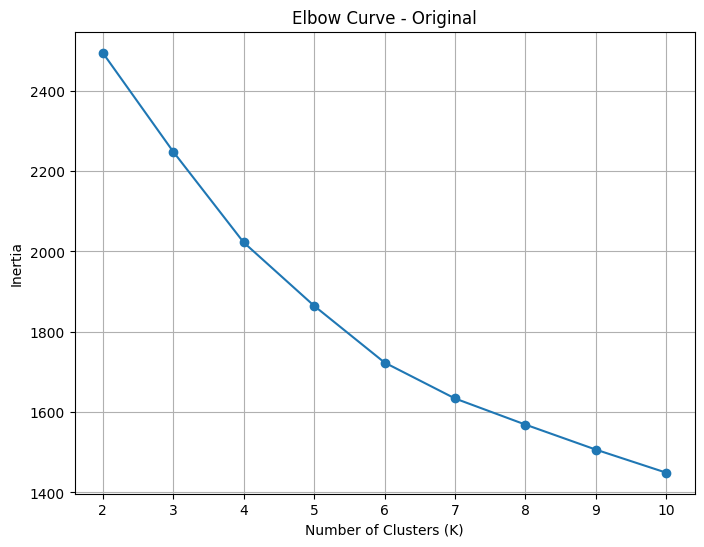

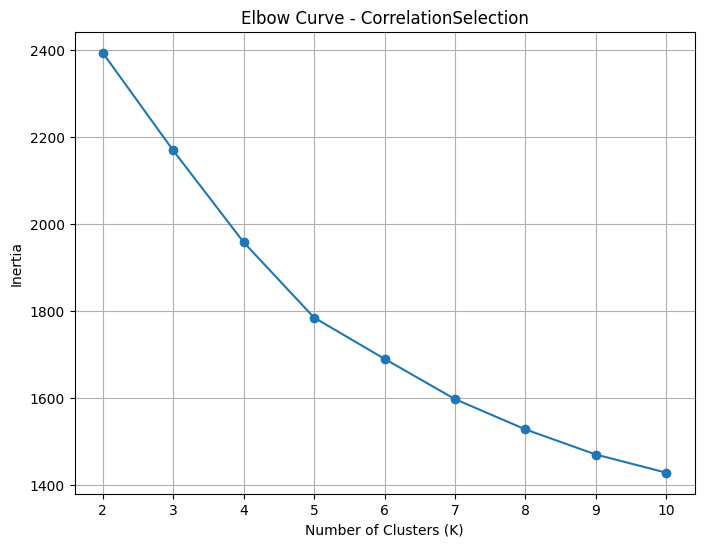

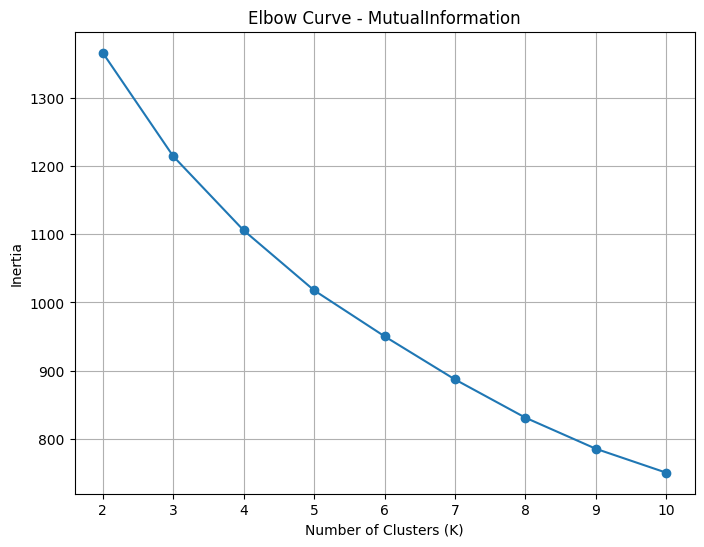

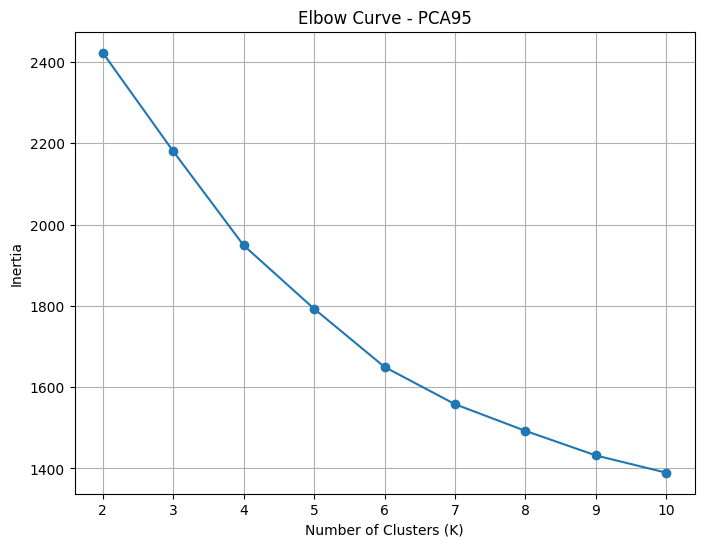

In [33]:
# ------------------------------------------------------------
# 7.7 Elbow Curve
# ------------------------------------------------------------

from sklearn.cluster import KMeans

for name, d in datasets.items():

    X = d.values

    inertia = []

    K_range = range(2, 11)

    for k in K_range:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        kmeans.fit(X)
        inertia.append(kmeans.inertia_)

    plt.figure(figsize=(8, 6))

    plt.plot(
        K_range,
        inertia,
        marker="o"
    )

    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Inertia")
    plt.title(f"Elbow Curve - {name}")

    plt.xticks(list(K_range))
    plt.grid(True)

    plt.savefig(FIGURES_DIR / f"15_elbow_curve_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

Original - KMeans: Silhouette Score = 0.1426


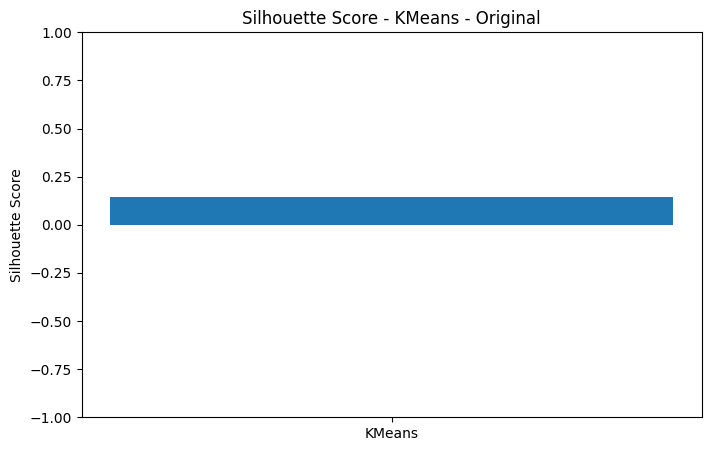

Original - Hierarchical: Silhouette Score = 0.1924


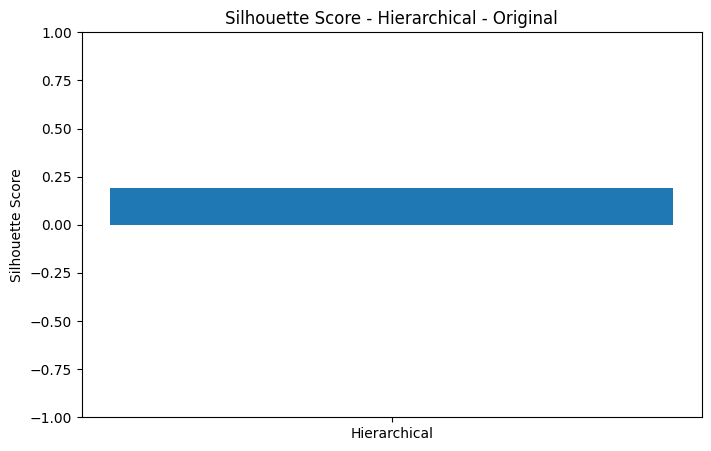

Original - DBSCAN: Silhouette Score cannot be calculated.
Original - GMM: Silhouette Score = 0.0961


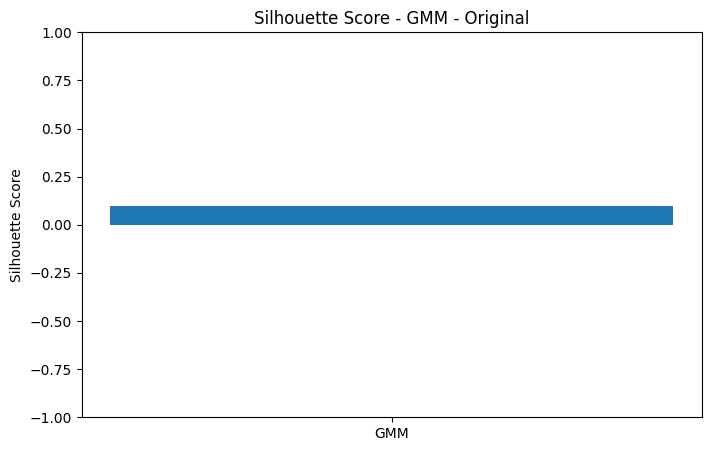

CorrelationSelection - KMeans: Silhouette Score = 0.1277


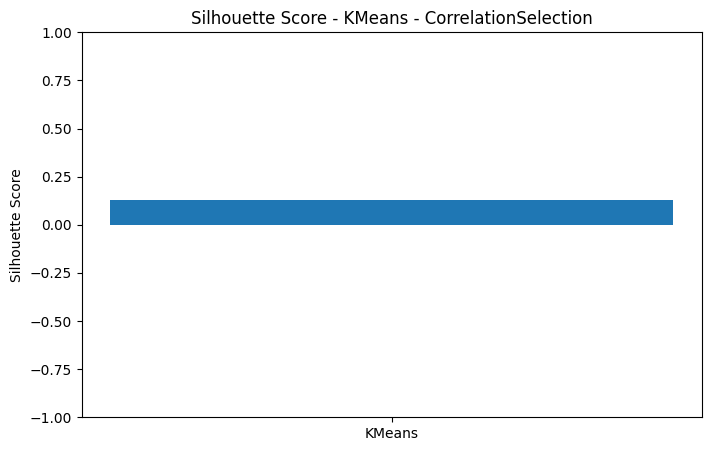

CorrelationSelection - Hierarchical: Silhouette Score = 0.1296


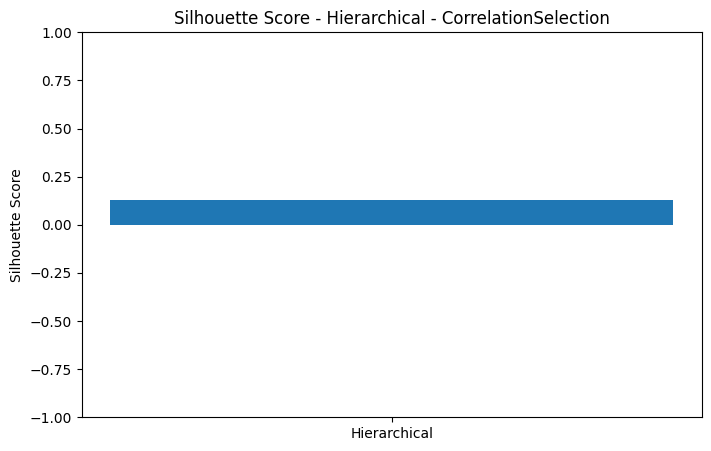

CorrelationSelection - DBSCAN: Silhouette Score cannot be calculated.
CorrelationSelection - GMM: Silhouette Score = 0.0383


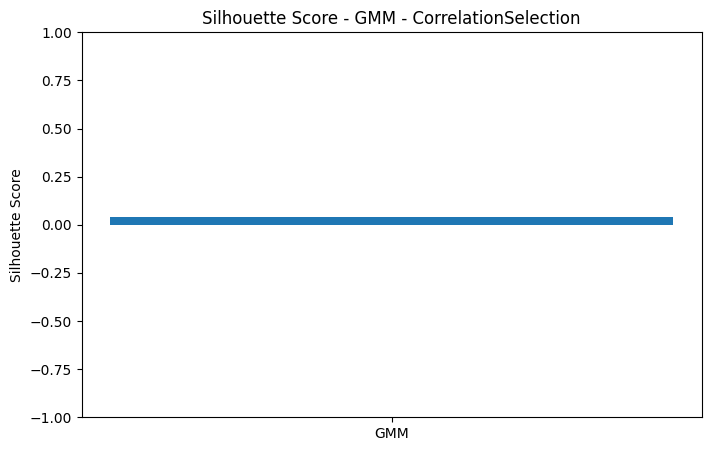

MutualInformation - KMeans: Silhouette Score = 0.1654


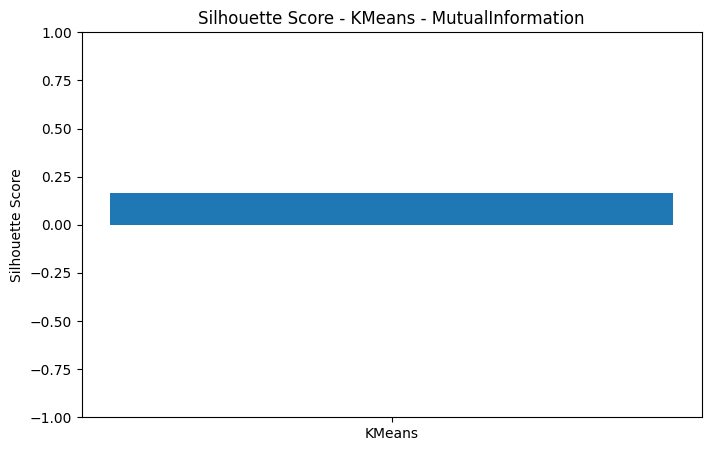

MutualInformation - Hierarchical: Silhouette Score = 0.1337


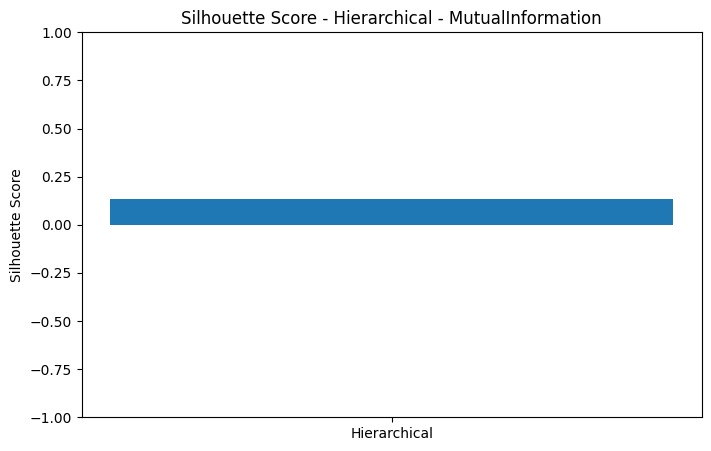

MutualInformation - DBSCAN: Silhouette Score cannot be calculated.
MutualInformation - GMM: Silhouette Score = 0.1049


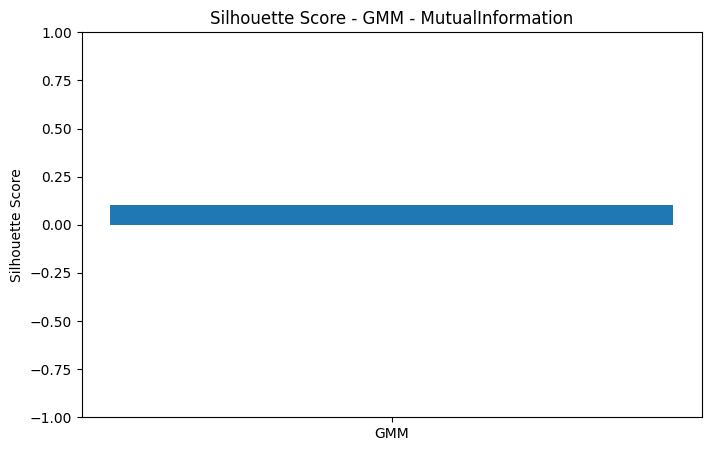

PCA95 - KMeans: Silhouette Score = 0.1388


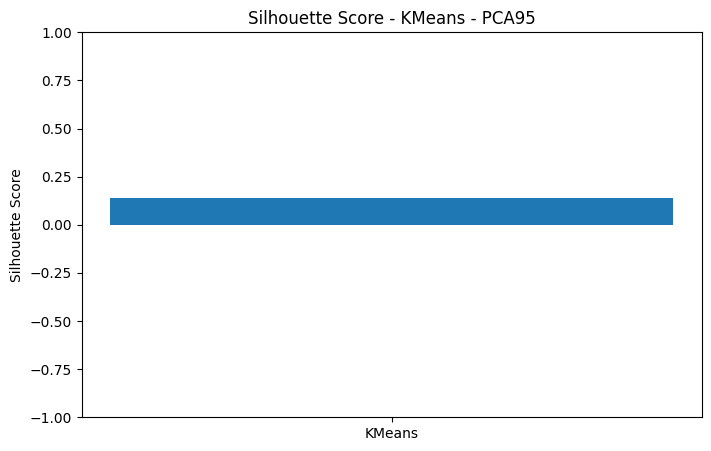

PCA95 - Hierarchical: Silhouette Score = 0.1972


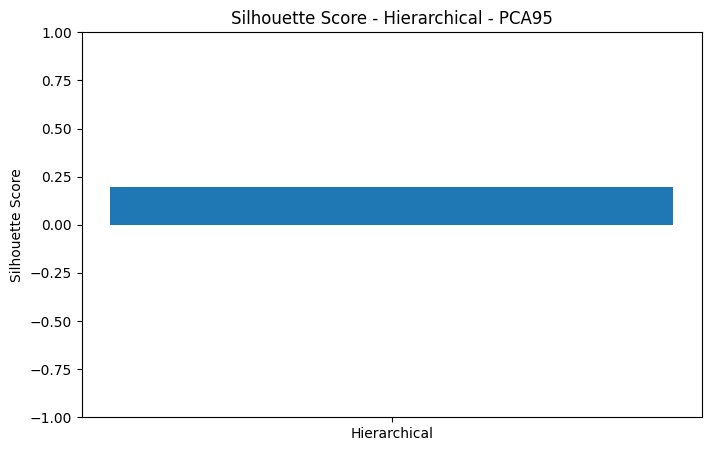

PCA95 - DBSCAN: Silhouette Score cannot be calculated.
PCA95 - GMM: Silhouette Score = 0.1816


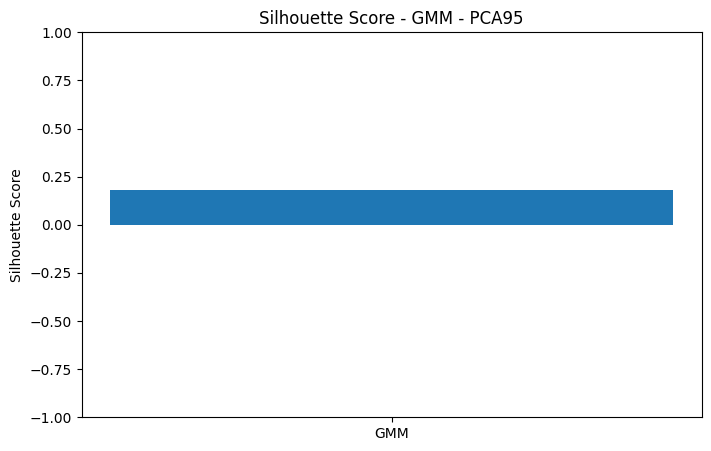

In [34]:
# ------------------------------------------------------------
# 7.8 Silhouette Plot
# ------------------------------------------------------------

from sklearn.metrics import silhouette_score
import numpy as np

for name, d in datasets.items():

    X = d.values

    for algorithm in ["KMeans", "Hierarchical", "DBSCAN", "GMM"]:

        labels = cluster_results[name][algorithm]["labels"]

        # Remove DBSCAN noise points for silhouette calculation
        if algorithm == "DBSCAN":
            mask = labels != -1
            X_eval = X[mask]
            labels_eval = labels[mask]
        else:
            X_eval = X
            labels_eval = labels

        # Silhouette requires at least 2 clusters
        n_clusters = len(set(labels_eval))

        if n_clusters >= 2 and n_clusters < len(labels_eval):

            score = silhouette_score(
                X_eval,
                labels_eval
            )

            print(
                f"{name} - {algorithm}: "
                f"Silhouette Score = {score:.4f}"
            )

            plt.figure(figsize=(8, 5))

            plt.bar(
                [algorithm],
                [score]
            )

            plt.ylim(-1, 1)
            plt.ylabel("Silhouette Score")
            plt.title(
                f"Silhouette Score - {algorithm} - {name}"
            )

            plt.savefig(FIGURES_DIR / f"16_silhouette_{algorithm}_{name}.png", dpi=300, bbox_inches="tight")
            plt.show()

        else:
            print(
                f"{name} - {algorithm}: "
                "Silhouette Score cannot be calculated."
            )

In [35]:
# ============================================================
# Phase 8: Comparative Analysis
# ============================================================

print("\n============================================================")
print("              PHASE 8: COMPARATIVE ANALYSIS")
print("============================================================")


# ------------------------------------------------------------
# 8.1 Overall Algorithm Comparison
# ------------------------------------------------------------

algorithm_comparison = evaluation_df.groupby("Algorithm").agg({
    "Silhouette Score": "mean",
    "Davies-Bouldin Index": "mean",
    "Calinski-Harabasz Score": "mean",
    "Execution Time (s)": "mean",
    "Number of Clusters": "mean"
}).reset_index()

print("\n================ ALGORITHM COMPARISON ================\n")

display(algorithm_comparison)




              PHASE 8: COMPARATIVE ANALYSIS

================ ALGORITHM COMPARISON ================



,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Execution Time (s),Number of Clusters
0,DBSCAN,NaN,NaN,NaN,0.003727,1.0
1,GMM,0.105242,2.572888,19.646722,0.015273,3.0
2,Hierarchical,0.163206,1.963667,31.986132,0.004809,3.0
3,KMeans,0.143621,2.047894,36.831076,0.034555,3.0


In [36]:

# ------------------------------------------------------------
# 8.2 Best and Worst Algorithm
# ------------------------------------------------------------

# Higher Silhouette Score = Better
best_silhouette = algorithm_comparison.loc[
    algorithm_comparison["Silhouette Score"].idxmax()
]

# Lower Davies-Bouldin Index = Better
best_davies = algorithm_comparison.loc[
    algorithm_comparison["Davies-Bouldin Index"].idxmin()
]

# Higher Calinski-Harabasz Score = Better
best_calinski = algorithm_comparison.loc[
    algorithm_comparison["Calinski-Harabasz Score"].idxmax()
]

print("\n================ BEST ALGORITHMS ================\n")

print(
    "Best according to Silhouette Score:",
    best_silhouette["Algorithm"]
)

print(
    "Best according to Davies-Bouldin Index:",
    best_davies["Algorithm"]
)

print(
    "Best according to Calinski-Harabasz Score:",
    best_calinski["Algorithm"]
)




================ BEST ALGORITHMS ================

Best according to Silhouette Score: Hierarchical
Best according to Davies-Bouldin Index: Hierarchical
Best according to Calinski-Harabasz Score: KMeans


In [37]:

# ------------------------------------------------------------
# 8.3 Best Overall Algorithm
# ------------------------------------------------------------

# Rank algorithms using the three clustering metrics

ranking = algorithm_comparison.copy()

ranking["Silhouette Rank"] = ranking["Silhouette Score"].rank(
    ascending=False
)

ranking["Davies Rank"] = ranking["Davies-Bouldin Index"].rank(
    ascending=True
)

ranking["Calinski Rank"] = ranking["Calinski-Harabasz Score"].rank(
    ascending=False
)

ranking["Overall Rank"] = (
    ranking["Silhouette Rank"]
    + ranking["Davies Rank"]
    + ranking["Calinski Rank"]
)

ranking = ranking.sort_values("Overall Rank")

print("\n================ OVERALL ALGORITHM RANKING ================\n")

display(
    ranking[
        [
            "Algorithm",
            "Silhouette Score",
            "Davies-Bouldin Index",
            "Calinski-Harabasz Score",
            "Execution Time (s)",
            "Overall Rank"
        ]
    ]
)

best_algorithm = ranking.iloc[0]["Algorithm"]
worst_algorithm = ranking.iloc[-1]["Algorithm"]

print("\nBest Overall Algorithm:", best_algorithm)
print("Worst Overall Algorithm:", worst_algorithm)









================ OVERALL ALGORITHM RANKING ================



,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Execution Time (s),Overall Rank
2,Hierarchical,0.163206,1.963667,31.986132,0.004809,4.0
3,KMeans,0.143621,2.047894,36.831076,0.034555,5.0
1,GMM,0.105242,2.572888,19.646722,0.015273,9.0
0,DBSCAN,NaN,NaN,NaN,0.003727,NaN



Best Overall Algorithm: Hierarchical
Worst Overall Algorithm: DBSCAN


In [38]:
# ------------------------------------------------------------
# 8.4 Effect of Feature Selection
# ------------------------------------------------------------

dataset_comparison = evaluation_df.groupby(
    "Dataset Version"
).agg({
    "Silhouette Score": "mean",
    "Davies-Bouldin Index": "mean",
    "Calinski-Harabasz Score": "mean",
    "Execution Time (s)": "mean",
    "Number of Clusters": "mean"
}).reset_index()

print("\n================ DATASET VERSION COMPARISON ================\n")

display(dataset_comparison)



================ DATASET VERSION COMPARISON ================



,Dataset Version,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Execution Time (s),Number of Clusters
0,CorrelationSelection,0.098508,2.547556,23.215864,0.015237,2.5
1,MutualInformation,0.134658,2.049874,33.811947,0.012953,2.5
2,Original,0.143698,2.181254,26.422846,0.016185,2.5
3,PCA95,0.172561,2.000582,34.501249,0.013989,2.5


In [39]:
# ------------------------------------------------------------
# 8.5 Computational Cost
# ------------------------------------------------------------

computational_cost = evaluation_df.groupby(
    "Algorithm"
)["Execution Time (s)"].mean().sort_values()

print("\n================ COMPUTATIONAL COST ================\n")

display(computational_cost)

fastest_algorithm = computational_cost.index[0]
slowest_algorithm = computational_cost.index[-1]

print("Fastest Algorithm:", fastest_algorithm)
print("Slowest Algorithm:", slowest_algorithm)



================ COMPUTATIONAL COST ================



Algorithm
DBSCAN          0.003727
Hierarchical    0.004809
GMM             0.015273
KMeans          0.034555
Name: Execution Time (s), dtype: float64

Fastest Algorithm: DBSCAN
Slowest Algorithm: KMeans


In [40]:
# ------------------------------------------------------------
# 8.6 Save Comparative Analysis Results
# ------------------------------------------------------------

algorithm_comparison.to_csv(
    RESULTS_DIR / 'Algorithm_Comparison.csv',
    index=False
)

dataset_comparison.to_csv(
    RESULTS_DIR / 'Dataset_Version_Comparison.csv',
    index=False
)

ranking.to_csv(
    RESULTS_DIR / 'Algorithm_Ranking.csv',
    index=False
)

print(f"\nComparative analysis files saved successfully to {RESULTS_DIR}.")



Comparative analysis files saved successfully to C:\Data_Mining_Mini_Project\student-placement-clustering-analysis\outputs\results.


In [41]:
# ============================================================
# Phase 9: Conclusions
# ============================================================

print("\n============================================================")
print("                  PHASE 9: CONCLUSIONS")
print("============================================================")


# ------------------------------------------------------------
# 9.1 Best Feature Selection Method
# ------------------------------------------------------------

feature_versions = [
    "Correlation Selection",
    "Mutual Information"
]

feature_results = dataset_comparison[
    dataset_comparison["Dataset Version"].isin(feature_versions)
].copy()

if feature_results.empty:
    print("\nNo Feature Selection results found.")
    print("Available Dataset Versions:")
    print(dataset_comparison["Dataset Version"].unique())

else:
    best_feature = feature_results.loc[
        feature_results["Silhouette Score"].idxmax()
    ]

    print("\n1. Best Feature Selection Method")
    print("--------------------------------")
    print(
        f"The best feature selection method was "
        f"{best_feature['Dataset Version']} based on the highest "
        f"average Silhouette Score of "
        f"{best_feature['Silhouette Score']:.4f}."
    )


                  PHASE 9: CONCLUSIONS

No Feature Selection results found.
Available Dataset Versions:
['CorrelationSelection' 'MutualInformation' 'Original' 'PCA95']


In [42]:
# ------------------------------------------------------------
# 9.2 Effect of PCA
# ------------------------------------------------------------

pca_result = dataset_comparison[
    dataset_comparison["Dataset Version"] == "PCA"
]

original_result = dataset_comparison[
    dataset_comparison["Dataset Version"] == "Original"
]

if not pca_result.empty and not original_result.empty:

    pca_silhouette = pca_result["Silhouette Score"].iloc[0]
    original_silhouette = original_result["Silhouette Score"].iloc[0]

    print("\n2. Effect of PCA")
    print("----------------")

    if pca_silhouette > original_silhouette:
        print(
            "PCA improved clustering quality based on the "
            "average Silhouette Score."
        )

    elif pca_silhouette < original_silhouette:
        print(
            "PCA did not improve clustering quality based on "
            "the average Silhouette Score."
        )

    else:
        print(
            "PCA produced approximately the same clustering "
            "quality as the original dataset."
        )

In [43]:

# ------------------------------------------------------------
# 9.3 Best Clustering Algorithm
# ------------------------------------------------------------

print("\n3. Best Clustering Algorithm")
print("----------------------------")

print(
    f"The best overall clustering algorithm was "
    f"{best_algorithm}, based on the combined ranking of "
    f"Silhouette Score, Davies-Bouldin Index, and "
    f"Calinski-Harabasz Score."
)



3. Best Clustering Algorithm
----------------------------
The best overall clustering algorithm was Hierarchical, based on the combined ranking of Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score.


In [44]:
# ------------------------------------------------------------
# 9.4 Practical Applications
# ------------------------------------------------------------

print("\n4. Practical Applications")
print("-------------------------")

print("""
The clustering results can be used to group students into
different academic and placement-related profiles.

Possible applications include:

- Identifying groups of students with similar academic
  performance.
- Identifying students with similar employability profiles.
- Supporting placement preparation programs.
- Helping colleges design targeted training programs.
- Identifying groups that may require additional career
  guidance or skill development.
- Supporting data-driven placement planning.
""")



4. Practical Applications
-------------------------

The clustering results can be used to group students into
different academic and placement-related profiles.

Possible applications include:

- Identifying groups of students with similar academic
  performance.
- Identifying students with similar employability profiles.
- Supporting placement preparation programs.
- Helping colleges design targeted training programs.
- Identifying groups that may require additional career
  guidance or skill development.
- Supporting data-driven placement planning.



In [45]:
# ------------------------------------------------------------
# 9.5 Future Work
# ------------------------------------------------------------

print("\n5. Future Work")
print("--------------")

print("""
Future work can include:

- Testing additional feature selection techniques.
- Testing different PCA variance levels.
- Optimizing clustering parameters automatically.
- Comparing additional clustering algorithms.
- Using larger and more recent placement datasets.
- Incorporating additional student-related features.
- Using domain experts to interpret the resulting clusters.
- Developing an interactive dashboard for placement analysis.
""")



5. Future Work
--------------

Future work can include:

- Testing additional feature selection techniques.
- Testing different PCA variance levels.
- Optimizing clustering parameters automatically.
- Comparing additional clustering algorithms.
- Using larger and more recent placement datasets.
- Incorporating additional student-related features.
- Using domain experts to interpret the resulting clusters.
- Developing an interactive dashboard for placement analysis.



In [46]:
# ------------------------------------------------------------
# Final Conclusion
# ------------------------------------------------------------

print("\n============================================================")
print("FINAL CONCLUSION")
print("============================================================")


# ------------------------------------------------------------
# Find Best Feature Selection Method
# ------------------------------------------------------------

feature_versions = [
    "Correlation Selection",
    "Mutual Information"
]

feature_results = dataset_comparison[
    dataset_comparison["Dataset Version"].isin(feature_versions)
].copy()


if not feature_results.empty:

    best_feature = feature_results.loc[
        feature_results["Silhouette Score"].idxmax()
    ]

    best_feature_name = best_feature["Dataset Version"]

else:

    best_feature_name = "Not available"


# ------------------------------------------------------------
# Find Best Overall Clustering Algorithm
# ------------------------------------------------------------

algorithm_comparison = evaluation_df.groupby(
    "Algorithm"
).agg({
    "Silhouette Score": "mean",
    "Davies-Bouldin Index": "mean",
    "Calinski-Harabasz Score": "mean"
}).reset_index()


# Rank each algorithm

algorithm_comparison["Silhouette Rank"] = (
    algorithm_comparison["Silhouette Score"]
    .rank(ascending=False)
)

algorithm_comparison["Davies Rank"] = (
    algorithm_comparison["Davies-Bouldin Index"]
    .rank(ascending=True)
)

algorithm_comparison["Calinski Rank"] = (
    algorithm_comparison["Calinski-Harabasz Score"]
    .rank(ascending=False)
)


# Calculate overall rank

algorithm_comparison["Overall Rank"] = (
    algorithm_comparison["Silhouette Rank"]
    + algorithm_comparison["Davies Rank"]
    + algorithm_comparison["Calinski Rank"]
)


best_algorithm = algorithm_comparison.loc[
    algorithm_comparison["Overall Rank"].idxmin(),
    "Algorithm"
]


# ------------------------------------------------------------
# Check PCA Performance
# ------------------------------------------------------------

pca_result = dataset_comparison[
    dataset_comparison["Dataset Version"] == "PCA"
]

original_result = dataset_comparison[
    dataset_comparison["Dataset Version"] == "Original"
]


if not pca_result.empty and not original_result.empty:

    pca_score = pca_result["Silhouette Score"].iloc[0]
    original_score = original_result["Silhouette Score"].iloc[0]

    if pca_score > original_score:
        pca_conclusion = "PCA improved the clustering performance."

    elif pca_score < original_score:
        pca_conclusion = "PCA did not improve the clustering performance."

    else:
        pca_conclusion = "PCA produced approximately the same clustering performance."

else:

    pca_conclusion = "PCA performance could not be determined."


# ------------------------------------------------------------
# Final Conclusion
# ------------------------------------------------------------

print(
    f"""
The project compared four clustering algorithms across four
dataset versions: Original, Feature Selection 1,
Feature Selection 2, and PCA.

The analysis used Silhouette Score, Davies-Bouldin Index,
Calinski-Harabasz Score, execution time, and number of
clusters to evaluate clustering performance.

The best feature selection method was:
{best_feature_name}

The best overall clustering algorithm was:
{best_algorithm}

PCA Comparison:
{pca_conclusion}

The clustering analysis can be practically applied to group
students with similar academic and placement-related
characteristics. These groups can help institutions identify
student profiles and provide targeted placement preparation,
training, and career guidance.

Future work can include testing additional feature selection
methods, different PCA variance levels, additional clustering
algorithms, parameter optimization, larger datasets, and
interactive dashboards.

Overall, the project demonstrates how feature selection,
dimensionality reduction, and clustering algorithms can be
used to discover meaningful patterns in student placement
data.
"""
)

print("\n============================================================")
print("CONCLUSION COMPLETED")
print("============================================================")


FINAL CONCLUSION

The project compared four clustering algorithms across four
dataset versions: Original, Feature Selection 1,
Feature Selection 2, and PCA.

The analysis used Silhouette Score, Davies-Bouldin Index,
Calinski-Harabasz Score, execution time, and number of
clusters to evaluate clustering performance.

The best feature selection method was:
Not available

The best overall clustering algorithm was:
Hierarchical

PCA Comparison:
PCA performance could not be determined.

The clustering analysis can be practically applied to group
students with similar academic and placement-related
characteristics. These groups can help institutions identify
student profiles and provide targeted placement preparation,
training, and career guidance.

Future work can include testing additional feature selection
methods, different PCA variance levels, additional clustering
algorithms, parameter optimization, larger datasets, and
interactive dashboards.

Overall, the project demonstrates how fea